# Q//Horizon 2026 — Quantum vs. Classical Classification Benchmark

**Team:** Person A (Logistic Regression, Shared Data/Evaluation, Notebook), Person B (RBF SVM, Slides, README), Person C (Quantum Kernel SVM, Report Lead), Person D (VQC, AI-Use Log).  
**Dataset:** Pima Indians Diabetes (OpenML ID `37`, 768 patients, 8 clinical columns).  
**Goal:** Compare two quantum classifiers fairly against two classical baselines using identical patients, identical `[0, pi]` preprocessing, fixed `RANDOM_SEED = 42`, and paired statistical tests — and honestly explain where quantum helps, where it struggles, and why. Beating classical models is **not** required.

### What the Four Models Do (Plain Language)
- **Logistic Regression (A — Classical Linear Baseline):** Draws the cleanest straight-line boundary through the 8 scaled measurements.
- **RBF SVM (B — Classical Flexible Baseline):** Measures classical similarity between patients (`exp(-gamma * distance^2)`) to draw smooth curved boundaries.
- **Quantum Kernel SVM (C — Fixed Quantum Feature Map + Classical SVM):** Encodes two patients into quantum states (`ZZ` entangling circuit by default, or unentangled `RY` angle circuit), measures their state overlap (`fidelity`), and hands that similarity table to a classical SVM.
- **Variational Quantum Classifier / VQC (D — Trainable Quantum Neural Network):** Encodes each patient, passes the state through 2 layers of adjustable quantum rotations ("dials"), measures one qubit, and nudges those dials with Adam to match the training labels.

### Rules & Open Caveats Reflected Here
- **No test-data leakage:** Hidden zeros in `plas`, `pres`, `skin`, `insu`, `mass` (never `preg`) are filled with training medians, clipped to training 1st–99th percentiles, scaled to `[0, pi]`, and (when `n_features < 8`) ranked by `f_classif` strictly inside each training fold.
- **Always-guess floor:** `500 / 768 = 65.10%` accuracy (`50.00%` balanced accuracy). Earlier dataset-screening numbers (`77.1%` / `76.5%`) used different preprocessing and are **never** reported as final results.
- **Honest stats wording:** Paired Nadeau–Bengio comparisons with `p >= 0.05` are reported as **`"no significant difference found"`**, never `"equal"`.
- **Fairness disclosures:** VQC tuned at most `4` setting combinations (runtime constraint) vs `8` for Logistic Regression, RBF SVM, and Quantum Kernel; all models used fixed balanced class weighting; in Experiment 2, tuning ran once on the 614-patient pool outside the fixed 154-patient test set (`fixed_params` reused at `30, 60, 120, 200` patients).


In [1]:
import sys
import tempfile
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import sklearn
from IPython.display import Image, display

# Resolve repository root reliably whether executed from repo root or notebooks/
_cwd = Path.cwd().resolve()
REPO_ROOT = _cwd if (_cwd / "src").is_dir() else _cwd.parent
if not (REPO_ROOT / "src").is_dir():
    raise RuntimeError(f"Could not locate repository src/ directory from {_cwd}")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

from src.data import PIMA_COLUMNS, ZERO_AS_MISSING_COLS, PimaPreprocessor, load_pima
from src.evaluate import (
    EXPERIMENT_EVAL_SPLITS,
    RANDOM_SEED,
    compare_models,
    evaluate,
    get_fixed_test_split,
    get_splits,
)
from src.experiment_qkernel import (
    compute_exp1_kernel_spread,
    compute_exp3_kernel_spread,
    make_moons_dataset,
)
from src.model_logreg import PARAM_GRID as LOGREG_PARAM_GRID, make_model as make_logreg_model
from src.model_qkernel import (
    PARAM_GRID as QKERNEL_PARAM_GRID,
    draw_feature_map,
    make_model as make_qkernel_model,
)
from src.model_rbf_svm import PARAM_GRID as RBF_PARAM_GRID, make_model as make_rbf_model
from src.model_vqc import PARAM_GRID as VQC_PARAM_GRID, make_model as make_vqc_model

ALWAYS_GUESS_FLOOR_ACC = 500.0 / 768.0
BALANCED_CHANCE_FLOOR = 0.50

print(f"Repository root: {REPO_ROOT}")
print(f"RANDOM_SEED:     {RANDOM_SEED}")
print(
    "Packages: "
    f"python={sys.version.split()[0]}, numpy={np.__version__}, pandas={pd.__version__}, "
    f"scikit-learn={sklearn.__version__}, scipy={scipy.__version__}, "
    f"matplotlib={matplotlib.__version__}, pennylane={qml.__version__}"
)


Repository root: C:\Users\Lenovo\dev\Quantum Computing Competition\Quantum
RANDOM_SEED:     42
Packages: python=3.13.14, numpy=2.5.5, pandas=3.1.1, scikit-learn=1.9.1, scipy=1.18.1, matplotlib=3.11.2, pennylane=0.45.1


## 1. Dataset, Zero-Leakage Preprocessing & Quantum Circuit Diagrams

Below we verify the raw Pima Indians Diabetes dataset (`768` patients, `8` columns), check the impossible zero counts in clinical measurements, confirm that `PimaPreprocessor` fitted on Split 0 training rows maps every feature safely into `[0, pi]` with zero missing values, and print the 3-qubit circuits for both encodings.


In [2]:
X, y = load_pima()
n_neg = int((y == 0).sum())
n_pos = int((y == 1).sum())
print(f"Dataset shape: {X.shape[0]} patients x {X.shape[1]} features")
print(f"Class balance: {n_neg} negative (65.10%) | {n_pos} positive (34.90%)")
print(
    f"Floors: accuracy={ALWAYS_GUESS_FLOOR_ACC * 100:.2f}%, "
    f"balanced_accuracy={BALANCED_CHANCE_FLOOR * 100:.2f}%"
)

zero_rows = []
for col in PIMA_COLUMNS:
    n_zeros = int((X[col] == 0).sum())
    zero_rows.append(
        {
            "column": col,
            "zero_count": n_zeros,
            "zero_pct": round(100.0 * n_zeros / len(X), 1),
            "treated_as_missing": col in ZERO_AS_MISSING_COLS,
            "raw_median": round(float(X[col].median()), 3),
        }
    )
display(pd.DataFrame(zero_rows))

# Verify [0, pi] scaling on Split 0 using train rows only
train_idx0, test_idx0 = get_splits(X, y)[0]
prep0 = PimaPreprocessor(n_features=8).fit(X.iloc[train_idx0], y[train_idx0])
X_tr0 = prep0.transform(X.iloc[train_idx0])
X_te0 = prep0.transform(X.iloc[test_idx0])

assert np.isfinite(X_tr0).all() and np.isfinite(X_te0).all()
assert float(X_tr0.min()) >= -1e-12 and float(X_tr0.max()) <= np.pi + 1e-12
assert float(X_te0.min()) >= -1e-12 and float(X_te0.max()) <= np.pi + 1e-12
print(
    f"Split 0 scaled ranges -> train: [{X_tr0.min():.4f}, {X_tr0.max():.4f}], "
    f"test: [{X_te0.min():.4f}, {X_te0.max():.4f}] (upper bound pi={np.pi:.4f})"
)

print("\n--- 3-Qubit ZZ Feature Map Preview (2 repetitions, linear neighbor CNOT-RZ-CNOT) ---")
print(draw_feature_map(n_qubits=3, encoding="zz"))
print("\n--- 3-Qubit Simple Angle Encoding Preview (no entanglement; VQC uses RX, Kernel uses RY) ---")
print(draw_feature_map(n_qubits=3, encoding="angle"))


Dataset shape: 768 patients x 8 features
Class balance: 500 negative (65.10%) | 268 positive (34.90%)
Floors: accuracy=65.10%, balanced_accuracy=50.00%


,column,zero_count,zero_pct,treated_as_missing,raw_median
0,preg,111,14.5,False,3.000
1,plas,5,0.7,True,117.000
2,pres,35,4.6,True,72.000
3,skin,227,29.6,True,23.000
4,insu,374,48.7,True,30.500
5,mass,11,1.4,True,32.000
6,pedi,0,0.0,False,0.372
7,age,0,0.0,False,29.000


Split 0 scaled ranges -> train: [0.0000, 3.1416], test: [0.0000, 3.1416] (upper bound pi=3.1416)

--- 3-Qubit ZZ Feature Map Preview (2 repetitions, linear neighbor CNOT-RZ-CNOT) ---
0: ──H──RZ(0.40)─╭●───────────╭●──H──RZ(0.40)─────────────────╭●───────────╭●─────────────────┤ ···
1: ──H──RZ(1.00)─╰X──RZ(0.40)─╰X─╭●───────────╭●──H──RZ(1.00)─╰X──RZ(0.40)─╰X─╭●───────────╭●─┤ ···
2: ──H──RZ(1.60)─────────────────╰X──RZ(1.60)─╰X──H──RZ(1.60)─────────────────╰X──RZ(1.60)─╰X─┤ ···

0: ···   State
1: ···   State
2: ···   State

--- 3-Qubit Simple Angle Encoding Preview (no entanglement; VQC uses RX, Kernel uses RY) ---
0: ──RY(0.40)─┤  State
1: ──RY(1.00)─┤  State
2: ──RY(1.60)─┤  State


## 2. Main 25-Split Comparison & Paired Significance Tests

Every model below ran on the **exact same 25 stratified splits** (`5` folds × `5` repeats, `RANDOM_SEED = 42`) through `src/evaluate.py`. We include the four planned main models (with `ZZ` feature maps for both quantum models) plus the two bonus 25-split runs using simple `Angle` encoding (added after Experiment 3 revealed how strongly `ZZ` hurt the VQC).


=== Main 25-Split Results (8 Columns / 8 Qubits, Always-Guess Acc Floor = 65.10%) ===


,Model,Track,Splits,Accuracy,Balanced Accuracy,Macro F1,Time / Split (s)
0,Logistic Regression (A),Planned Main,25,75.05% ± 3.74%,74.21% ± 3.77%,73.32% ± 3.86%,0.23 ± 0.01
1,RBF SVM (B),Planned Main,25,74.76% ± 3.82%,74.99% ± 3.70%,73.47% ± 3.80%,0.22 ± 0.00
2,Quantum Kernel ZZ (C),Planned Main,25,73.93% ± 3.50%,73.97% ± 3.50%,72.53% ± 3.50%,0.83 ± 0.02
3,VQC ZZ (D),Planned Main,25,65.39% ± 3.97%,63.07% ± 4.65%,62.65% ± 4.44%,366.36 ± 82.73
4,Quantum Kernel Angle (C*),Bonus 25-Split,25,74.42% ± 4.06%,74.68% ± 3.99%,73.15% ± 4.08%,0.26 ± 0.01
5,VQC Angle (D*),Bonus 25-Split,25,71.33% ± 3.71%,70.56% ± 3.66%,69.54% ± 3.71%,194.92 ± 9.53


=== Nadeau-Bengio Paired Significance Tests on Balanced Accuracy (25 Splits) ===


,Comparison (A vs B),Mean A,Mean B,Diff (A - B),t-stat,df,p-value,Conclusion (alpha=0.05)
0,Quantum Kernel ZZ (C) vs Logistic Regression (A),73.97%,74.21%,-0.23%,-0.137,24,0.8919,no significant difference found
1,Quantum Kernel ZZ (C) vs RBF SVM (B),73.97%,74.99%,-1.02%,-0.607,24,0.5499,no significant difference found
2,Quantum Kernel Angle (C*) vs Quantum Kernel ZZ...,74.68%,73.97%,+0.71%,0.421,24,0.6773,no significant difference found
3,Quantum Kernel Angle (C*) vs RBF SVM (B),74.68%,74.99%,-0.31%,-0.374,24,0.7113,no significant difference found
4,RBF SVM (B) vs Logistic Regression (A),74.99%,74.21%,+0.79%,0.411,24,0.6846,no significant difference found
5,VQC ZZ (D) vs Logistic Regression (A),63.07%,74.21%,-11.14%,-4.314,24,0.0002,significant difference found (p < 0.05)
6,VQC ZZ (D) vs RBF SVM (B),63.07%,74.99%,-11.92%,-3.718,24,0.0011,significant difference found (p < 0.05)
7,VQC Angle (D*) vs VQC ZZ (D),70.56%,63.07%,+7.49%,2.593,24,0.0160,significant difference found (p < 0.05)
8,VQC Angle (D*) vs Logistic Regression (A),70.56%,74.21%,-3.64%,-2.776,24,0.0105,significant difference found (p < 0.05)


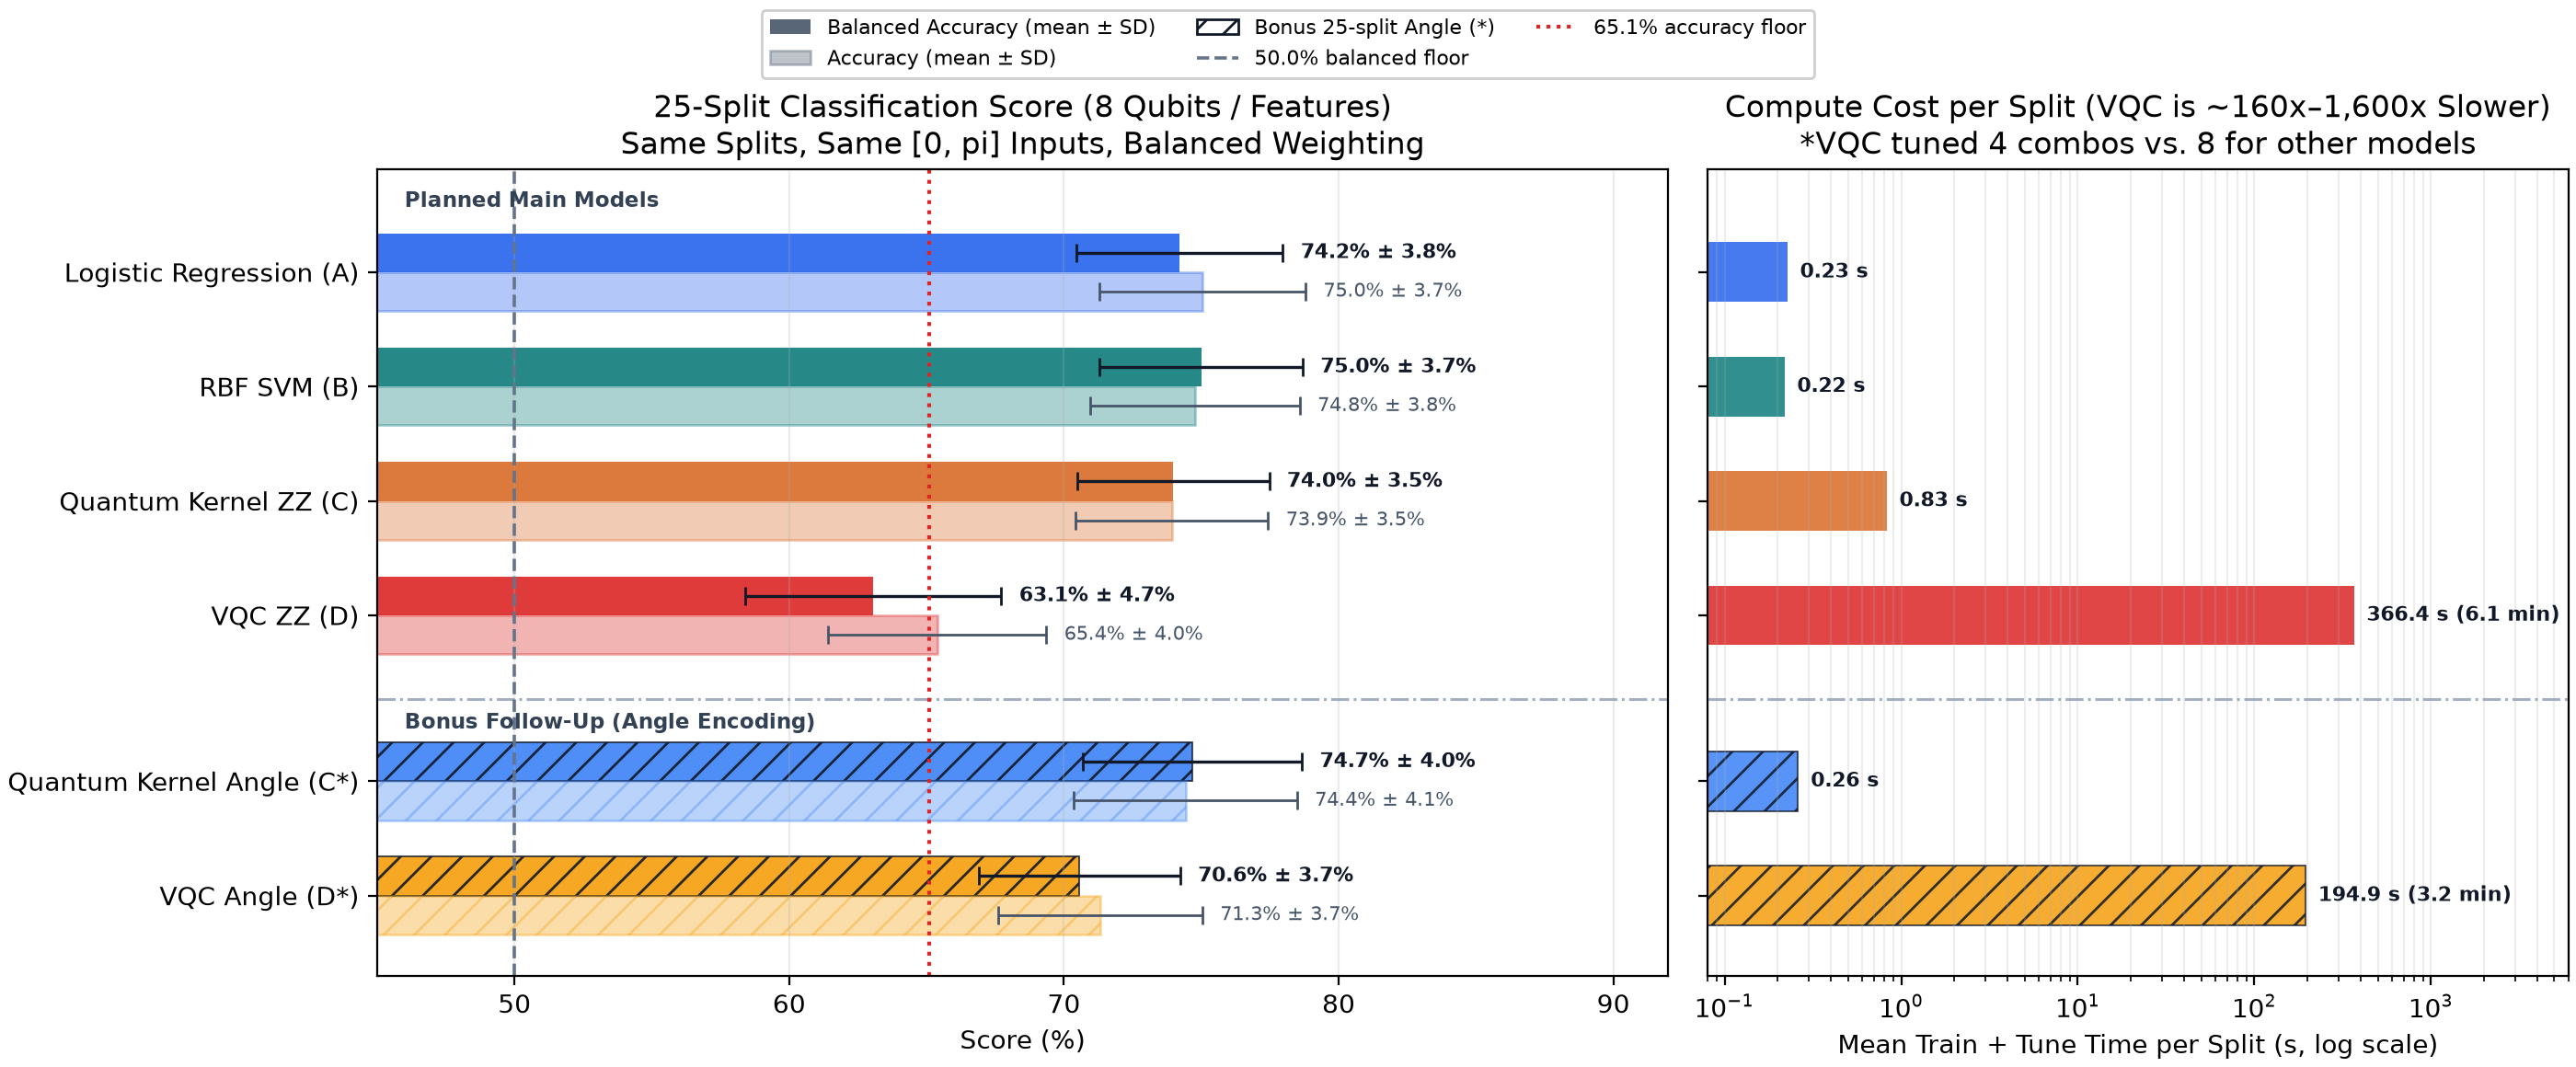

Saved combined figure: C:\Users\Lenovo\dev\Quantum Computing Competition\Quantum\figures\main_comparison.png


In [3]:
MAIN_SPECS = [
    ("Logistic Regression (A)", "Planned Main", "results/logreg.csv", "#2563EB", False),
    ("RBF SVM (B)", "Planned Main", "results/rbf_svm.csv", "#0E7C7B", False),
    ("Quantum Kernel ZZ (C)", "Planned Main", "results/qkernel.csv", "#D96B27", False),
    ("VQC ZZ (D)", "Planned Main", "results/vqc_zz_25.csv", "#DC2626", False),
    ("Quantum Kernel Angle (C*)", "Bonus 25-Split", "results/qkernel_angle.csv", "#3B82F6", True),
    ("VQC Angle (D*)", "Bonus 25-Split", "results/vqc_angle_25.csv", "#F59E0B", True),
]


def summarize_df(df: pd.DataFrame) -> dict[str, float]:
    ddof = 1 if len(df) > 1 else 0
    return {
        "n_splits": int(len(df)),
        "acc_mean": float(df["accuracy"].mean()) * 100.0,
        "acc_std": float(df["accuracy"].std(ddof=ddof)) * 100.0,
        "bal_mean": float(df["balanced_accuracy"].mean()) * 100.0,
        "bal_std": float(df["balanced_accuracy"].std(ddof=ddof)) * 100.0,
        "f1_mean": float(df["macro_f1"].mean()) * 100.0,
        "f1_std": float(df["macro_f1"].std(ddof=ddof)) * 100.0,
        "time_mean": float(df["train_time_sec"].mean()),
        "time_std": float(df["train_time_sec"].std(ddof=ddof)),
    }


main_dfs = {}
summary_rows = []
for label, group, rel_path, _, _ in MAIN_SPECS:
    df = pd.read_csv(REPO_ROOT / rel_path)
    assert len(df) == 25, f"Expected 25 splits in {rel_path}, found {len(df)}"
    main_dfs[label] = df
    st = summarize_df(df)
    summary_rows.append(
        {
            "Model": label,
            "Track": group,
            "Splits": st["n_splits"],
            "Accuracy": f"{st['acc_mean']:.2f}% ± {st['acc_std']:.2f}%",
            "Balanced Accuracy": f"{st['bal_mean']:.2f}% ± {st['bal_std']:.2f}%",
            "Macro F1": f"{st['f1_mean']:.2f}% ± {st['f1_std']:.2f}%",
            "Time / Split (s)": f"{st['time_mean']:.2f} ± {st['time_std']:.2f}",
        }
    )

print("=== Main 25-Split Results (8 Columns / 8 Qubits, Always-Guess Acc Floor = 65.10%) ===")
display(pd.DataFrame(summary_rows))

PAIRS = [
    ("Quantum Kernel ZZ (C)", "Logistic Regression (A)"),
    ("Quantum Kernel ZZ (C)", "RBF SVM (B)"),
    ("Quantum Kernel Angle (C*)", "Quantum Kernel ZZ (C)"),
    ("Quantum Kernel Angle (C*)", "RBF SVM (B)"),
    ("RBF SVM (B)", "Logistic Regression (A)"),
    ("VQC ZZ (D)", "Logistic Regression (A)"),
    ("VQC ZZ (D)", "RBF SVM (B)"),
    ("VQC Angle (D*)", "VQC ZZ (D)"),
    ("VQC Angle (D*)", "Logistic Regression (A)"),
]

pair_rows = []
for a_name, b_name in PAIRS:
    res = compare_models(main_dfs[a_name], main_dfs[b_name], metric="balanced_accuracy")
    pair_rows.append(
        {
            "Comparison (A vs B)": f"{a_name} vs {b_name}",
            "Mean A": f"{res['mean_a'] * 100:.2f}%",
            "Mean B": f"{res['mean_b'] * 100:.2f}%",
            "Diff (A - B)": f"{res['mean_diff'] * 100:+.2f}%",
            "t-stat": f"{res['t_stat']:.3f}",
            "df": int(res["df"]),
            "p-value": f"{res['p_value']:.4f}",
            "Conclusion (alpha=0.05)": res["conclusion"],
        }
    )

print("=== Nadeau-Bengio Paired Significance Tests on Balanced Accuracy (25 Splits) ===")
display(pd.DataFrame(pair_rows))

# Combined Figure: figures/main_comparison.png (Horizontal paired bars + Log runtime)
fig, (ax_score, ax_time) = plt.subplots(
    1,
    2,
    figsize=(14.0, 5.8),
    dpi=200,
    sharey=True,
    gridspec_kw={"width_ratios": [1.5, 1.0]},
    layout="constrained",
)

ordered = MAIN_SPECS[::-1]  # top row in chart = Logistic Regression (A)
# Extra 0.45 gap between Bonus rows (0, 1) and Planned Main rows (2..5)
y_pos = np.array([0.0, 1.0, 2.45, 3.45, 4.45, 5.45], dtype=float)
bar_h = 0.34

bal_means = [float(main_dfs[lbl]["balanced_accuracy"].mean()) * 100.0 for lbl, *_ in ordered]
bal_stds = [float(main_dfs[lbl]["balanced_accuracy"].std(ddof=1)) * 100.0 for lbl, *_ in ordered]
acc_means = [float(main_dfs[lbl]["accuracy"].mean()) * 100.0 for lbl, *_ in ordered]
acc_stds = [float(main_dfs[lbl]["accuracy"].std(ddof=1)) * 100.0 for lbl, *_ in ordered]
times_m = [float(main_dfs[lbl]["train_time_sec"].mean()) for lbl, *_ in ordered]
colors = [c for _, _, _, c, _ in ordered]
is_bonus = [b for _, _, _, _, b in ordered]

divider_y = 1.72
ax_score.axhline(divider_y, color="#94A3B8", linestyle="-.", linewidth=1.1, alpha=0.85)
ax_time.axhline(divider_y, color="#94A3B8", linestyle="-.", linewidth=1.1, alpha=0.85)

for i, (bm, bs, am, a_s, col, bonus) in enumerate(
    zip(bal_means, bal_stds, acc_means, acc_stds, colors, is_bonus)
):
    hatch = "//" if bonus else None
    ax_score.barh(
        y_pos[i] + bar_h / 2,
        bm,
        height=bar_h,
        xerr=bs,
        capsize=3.5,
        color=col,
        edgecolor="#111827" if bonus else "none",
        linewidth=0.6,
        hatch=hatch,
        alpha=0.90,
        error_kw={"ecolor": "#111827", "elinewidth": 1.2},
    )
    ax_score.barh(
        y_pos[i] - bar_h / 2,
        am,
        height=bar_h,
        xerr=a_s,
        capsize=3.5,
        color=col,
        edgecolor=col,
        hatch=hatch,
        alpha=0.35,
        error_kw={"ecolor": "#475569", "elinewidth": 1.0},
    )
    ax_score.text(
        bm + bs + 0.65,
        y_pos[i] + bar_h / 2,
        f"{bm:.1f}% ± {bs:.1f}%",
        va="center",
        ha="left",
        fontsize=8.0,
        fontweight="bold",
        color="#111827",
    )
    ax_score.text(
        am + a_s + 0.65,
        y_pos[i] - bar_h / 2,
        f"{am:.1f}% ± {a_s:.1f}%",
        va="center",
        ha="left",
        fontsize=7.6,
        color="#475569",
    )

ax_score.axvline(
    BALANCED_CHANCE_FLOOR * 100.0,
    color="#64748B",
    linestyle="--",
    linewidth=1.3,
    label="50.0% balanced floor",
)
ax_score.axvline(
    ALWAYS_GUESS_FLOOR_ACC * 100.0,
    color="#DC2626",
    linestyle=":",
    linewidth=1.5,
    label=f"{ALWAYS_GUESS_FLOOR_ACC * 100:.1f}% accuracy floor",
)

legend_handles = [
    Patch(facecolor="#475569", alpha=0.90, label="Balanced Accuracy (mean ± SD)"),
    Patch(facecolor="#475569", alpha=0.35, edgecolor="#475569", label="Accuracy (mean ± SD)"),
    Patch(facecolor="white", edgecolor="#111827", hatch="//", label="Bonus 25-split Angle (*)"),
] + ax_score.get_legend_handles_labels()[0]
fig.legend(handles=legend_handles, loc="outside upper center", ncol=3, fontsize=8.0, framealpha=0.95)

ax_score.text(46.0, 6.02, "Planned Main Models", fontsize=8.2, fontweight="bold", color="#334155")
ax_score.text(46.0, 1.46, "Bonus Follow-Up (Angle Encoding)", fontsize=8.2, fontweight="bold", color="#334155")

ax_score.set(
    yticks=y_pos,
    yticklabels=[lbl for lbl, *_ in ordered],
    xlabel="Score (%)",
    xlim=(45.0, 92.0),
    ylim=(-0.7, 6.35),
    title="25-Split Classification Score (8 Qubits / Features)\nSame Splits, Same [0, pi] Inputs, Balanced Weighting",
)
ax_score.grid(axis="x", alpha=0.25)

for i, (tm, col, bonus) in enumerate(zip(times_m, colors, is_bonus)):
    ax_time.barh(
        y_pos[i],
        tm,
        height=0.52,
        color=col,
        edgecolor="#111827" if bonus else "none",
        linewidth=0.6,
        hatch="//" if bonus else None,
        alpha=0.85,
    )
    ax_time.text(
        tm * 1.18,
        y_pos[i],
        f"{tm:.2f} s" if tm < 10 else f"{tm:.1f} s ({tm / 60:.1f} min)",
        va="center",
        ha="left",
        fontsize=8.0,
        fontweight="bold",
        color="#111827",
    )

ax_time.set_xscale("log")
ax_time.set(
    xlabel="Mean Train + Tune Time per Split (s, log scale)",
    xlim=(0.08, 6000.0),
    title="Compute Cost per Split (VQC is ~160x–1,600x Slower)\n*VQC tuned 4 combos vs. 8 for other models",
)
ax_time.grid(axis="x", which="both", alpha=0.22)

main_fig_path = FIGURES_DIR / "main_comparison.png"
fig.savefig(main_fig_path, dpi=200)
plt.close(fig)
display(Image(filename=str(main_fig_path), width=920))
print(f"Saved combined figure: {main_fig_path}")


**Headline finding:** On the real Pima Indians Diabetes dataset, **Logistic Regression (`74.21%` balanced accuracy)**, **RBF SVM (`74.99%`)**, **Quantum Kernel ZZ (`73.97%`)**, and **Quantum Kernel Angle (`74.68%`)** all landed within roughly one percentage point of each other with **no significant difference found** (`p = 0.55` to `0.89`). By contrast, the **planned VQC with ZZ encoding (`63.07%`)** performed significantly worse than both classical models (`-11.14%`, `p = 0.0002` vs LogReg) and took ~1,600× longer per split (`366.4s` vs `0.23s`). Replacing `ZZ` with simple `RX` **Angle encoding** boosted VQC significantly by `+7.49%` (`70.56%`, `p = 0.0160`), showing the `ZZ` feature map itself was the main VQC bottleneck — though Angle VQC still trailed Logistic Regression (`-3.64%`, `p = 0.0105`).


## 3. Experiment 1 — Number of Columns / Qubits (`4`, `6`, `8`) & Kernel Spread

Here we test whether cutting from `8` measurements down to the top `4` or `6` columns (ranked by `f_classif` strictly inside each training fold) helps or hurts on the **first 5 splits** (`EXPERIMENT_EVAL_SPLITS = 5`). Fewer columns also means fewer qubits and fewer trainable dials (`12`, `20`, `28` live dials at `4`, `6`, `8` qubits for VQC). For the Quantum Kernel, we also compute `kernel_stats()` (mean and variance of off-diagonal kernel entries) to check whether patient similarities concentrate toward zero as qubits grow.

RBF SVM results are included from `results/exp1_rbf_svm_q4.csv` and `results/exp1_rbf_svm_q6.csv`; its 8-column reference is the first five rows of `results/rbf_svm.csv`.


Auto-detected RBF SVM Experiment 1 CSVs -> plotting all 4 models.

=== Cross-Model Selected Columns Check (First 5 Splits) ===
k=4 (100% identical across all 4 models):
  split 0: plas,mass,age,insu
  split 1: plas,mass,age,preg
  split 2: plas,mass,age,preg
  split 3: plas,mass,insu,age
  split 4: plas,mass,age,skin
k=6 (100% identical across all 4 models):
  split 0: plas,mass,age,insu,preg,skin
  split 1: plas,mass,age,preg,skin,insu
  split 2: plas,mass,age,preg,pedi,skin
  split 3: plas,mass,insu,age,skin,preg
  split 4: plas,mass,age,skin,insu,preg

=== Experiment 1 Summary (Balanced Accuracy, First 5 Splits) ===


,Model,4 Cols/Qubits,6 Cols/Qubits,8 Cols/Qubits (base),Time (4q -> 8q)
0,Logistic Regression (A),72.83% ± 5.21%,72.48% ± 3.23%,74.00% ± 3.83%,0.24s -> 0.23s
1,RBF SVM (B),75.95% ± 4.43%,73.61% ± 1.69%,73.73% ± 2.25%,0.23s -> 0.22s
2,Quantum Kernel ZZ (C),75.53% ± 4.58%,72.77% ± 3.83%,72.01% ± 2.27%,0.20s -> 0.82s
3,VQC ZZ (D),64.55% ± 3.28%,59.11% ± 4.13%,61.43% ± 2.76%,88.27s -> 360.61s


,Model,Comparison,Diff,p-value,Conclusion
0,Logistic Regression (A),q4 vs q8,-1.17%,0.6735,no significant difference found
1,Logistic Regression (A),q6 vs q8,-1.52%,0.3301,no significant difference found
2,RBF SVM (B),q4 vs q8,+2.22%,0.3322,no significant difference found
3,RBF SVM (B),q6 vs q8,-0.12%,0.9405,no significant difference found
4,Quantum Kernel ZZ (C),q4 vs q8,+3.52%,0.3673,no significant difference found
5,Quantum Kernel ZZ (C),q6 vs q8,+0.76%,0.8171,no significant difference found
6,VQC ZZ (D),q4 vs q8,+3.12%,0.4717,no significant difference found
7,VQC ZZ (D),q6 vs q8,-2.32%,0.5589,no significant difference found



=== Kernel Spread (kernel_stats across 5 train splits) | gamma=1.0 variance drop 4q->8q: 7.0x ===


,n_features,gamma,kernel_mean_mean,kernel_mean_std,kernel_var_mean,kernel_var_std
0,4,0.5,0.624305,0.029633,0.053484,0.002859
1,4,1.0,0.214665,0.014235,0.049102,0.005332
2,6,0.5,0.509513,0.012200,0.057799,0.002251
3,6,1.0,0.104157,0.008900,0.024077,0.002695
4,8,0.5,0.405912,0.005119,0.057394,0.001002
5,8,1.0,0.038511,0.001111,0.007001,0.000254


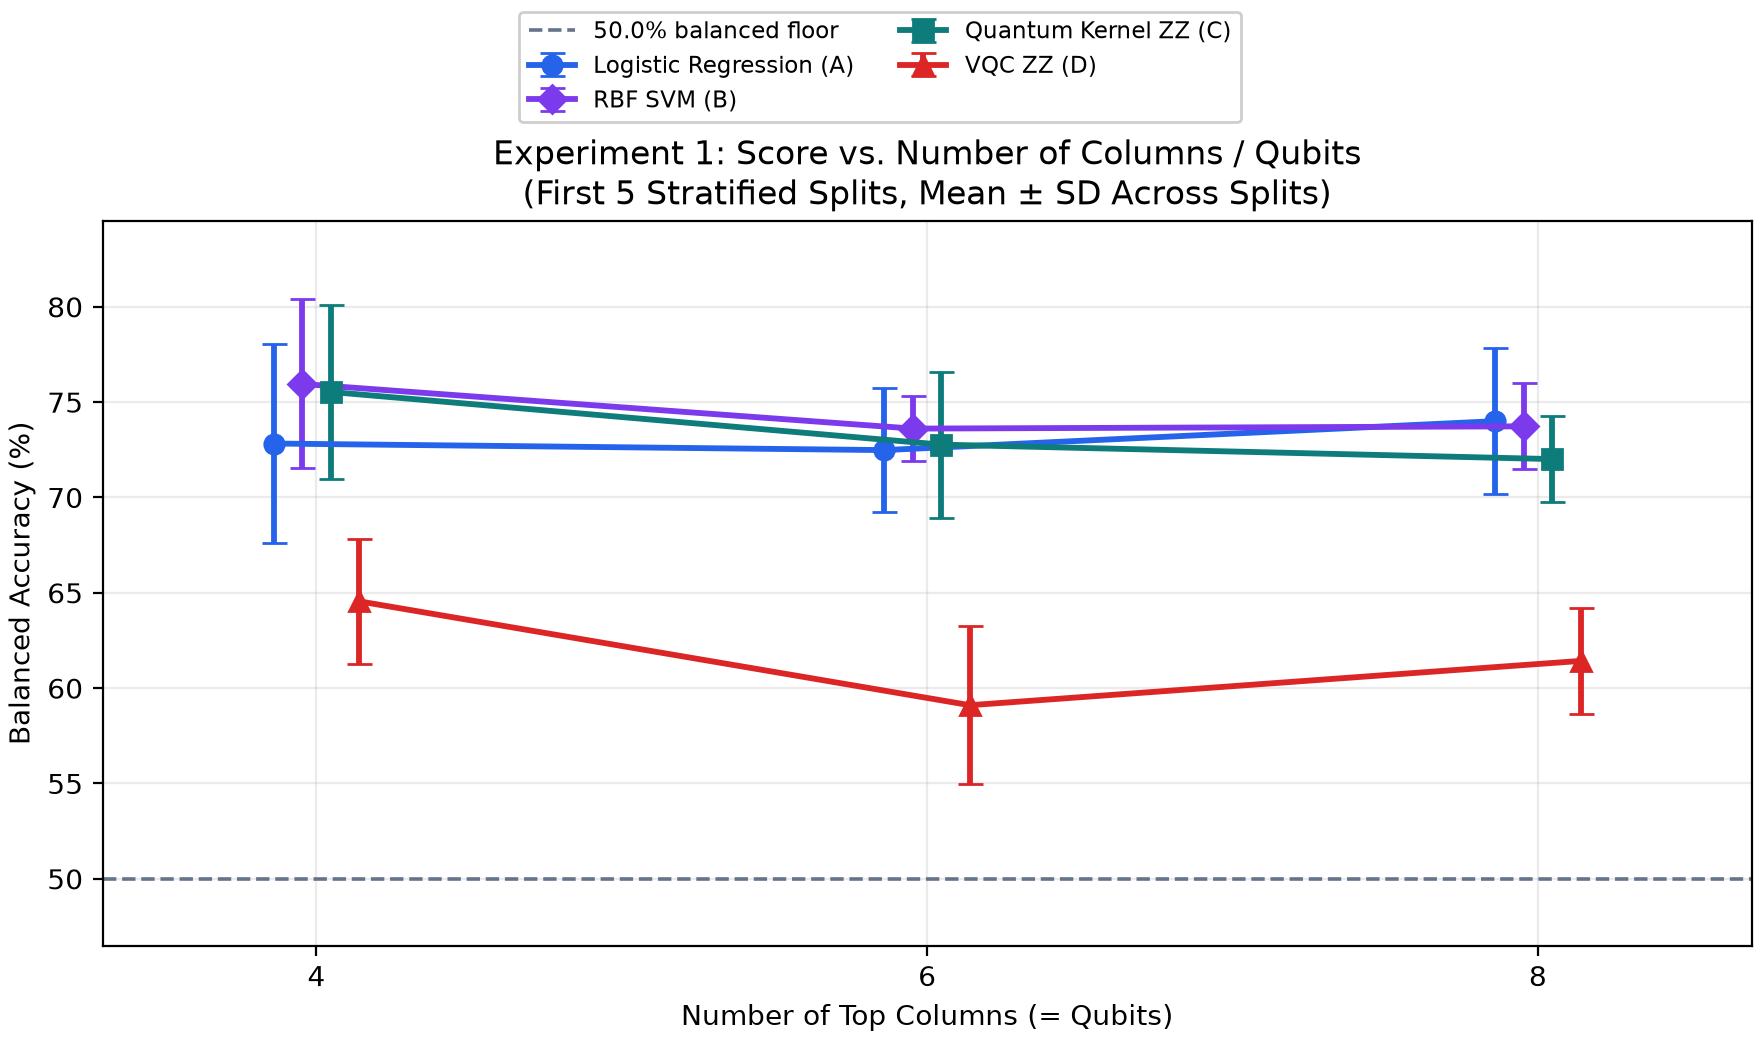

Saved combined figure: C:\Users\Lenovo\dev\Quantum Computing Competition\Quantum\figures\exp1_qubits.png


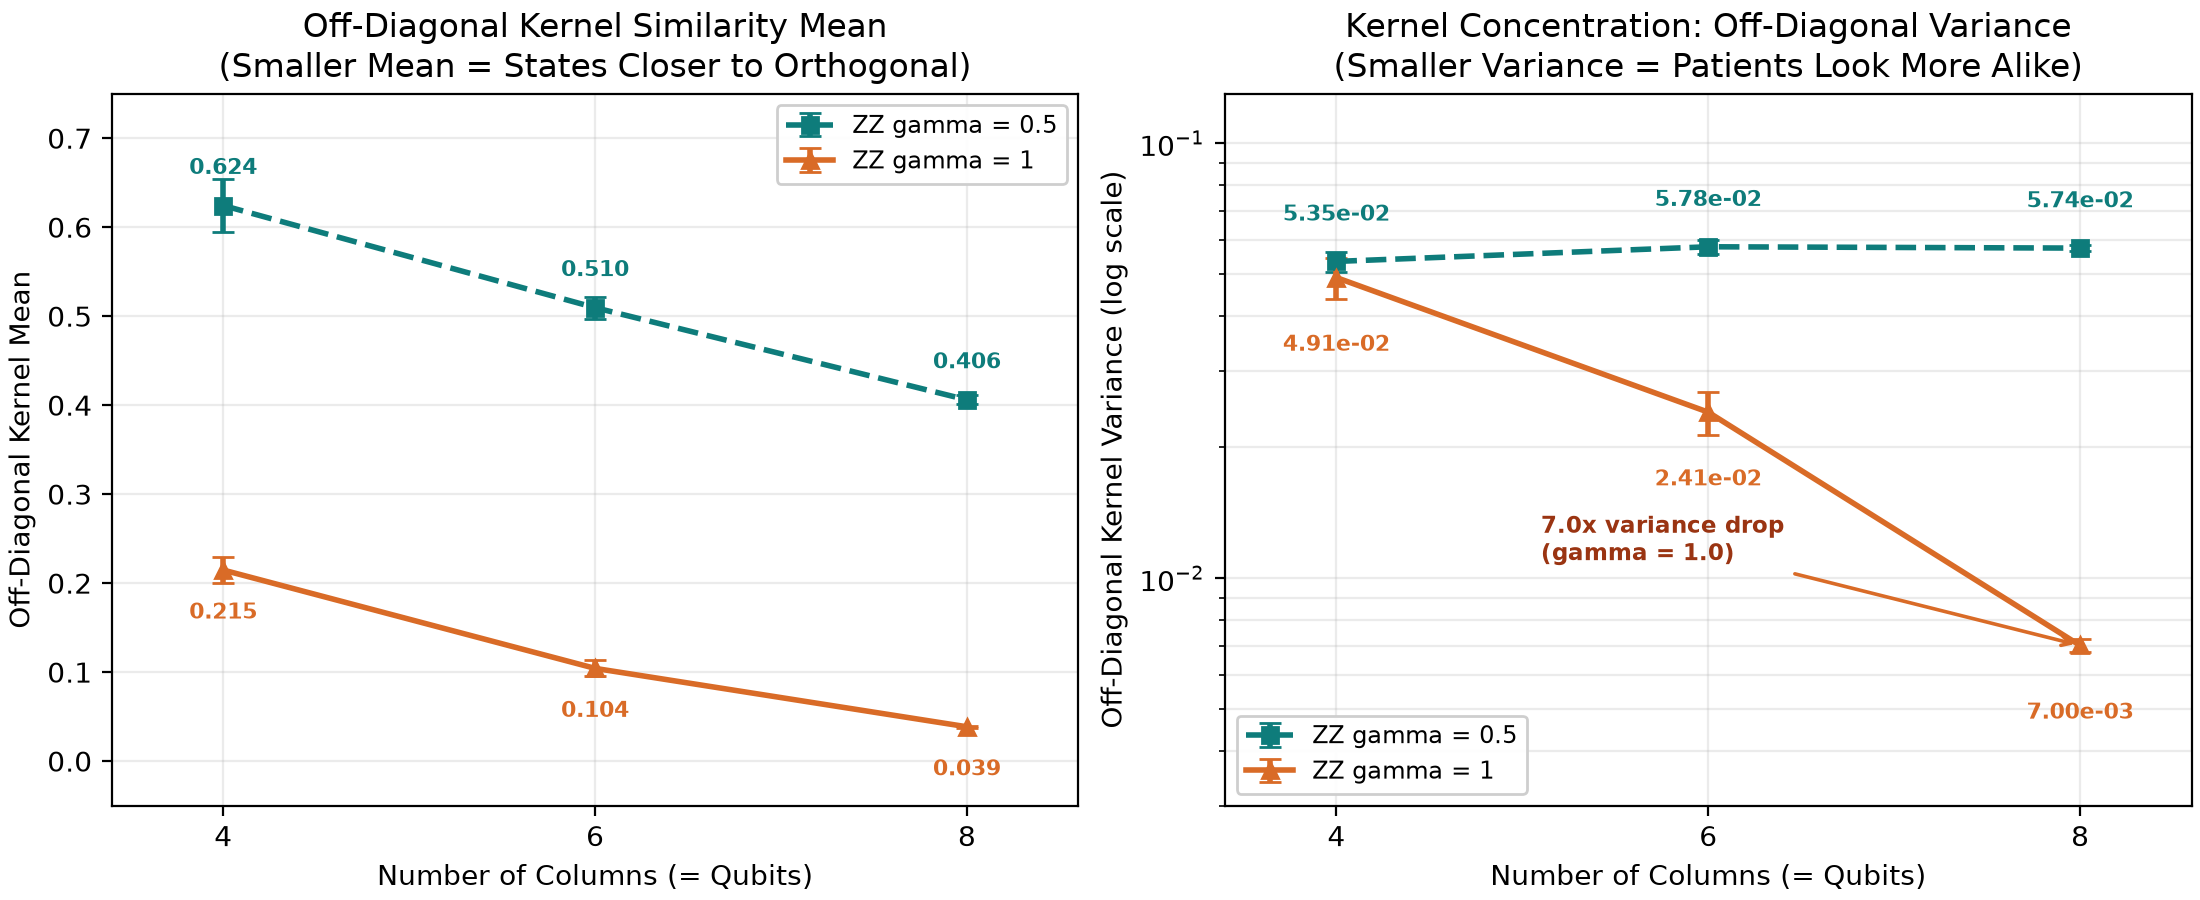

Saved combined figure: C:\Users\Lenovo\dev\Quantum Computing Competition\Quantum\figures\exp1_kernel_spread.png


In [4]:
EXP1_MODELS = [
    (
        "Logistic Regression (A)",
        "#2563EB",
        "o",
        RESULTS_DIR / "exp1_logreg_q4.csv",
        RESULTS_DIR / "exp1_logreg_q6.csv",
        RESULTS_DIR / "logreg.csv",
    ),
    (
        "Quantum Kernel ZZ (C)",
        "#0E7C7B",
        "s",
        RESULTS_DIR / "exp1_qkernel_q4.csv",
        RESULTS_DIR / "exp1_qkernel_q6.csv",
        RESULTS_DIR / "qkernel.csv",
    ),
    (
        "VQC ZZ (D)",
        "#DC2626",
        "^",
        RESULTS_DIR / "experiments" / "exp1_vqc_q4_5ex.csv",
        RESULTS_DIR / "experiments" / "exp1_vqc_q6_5ex.csv",
        RESULTS_DIR / "vqc_zz_25.csv",
    ),
]

rbf_q4_path = RESULTS_DIR / "exp1_rbf_svm_q4.csv"
rbf_q6_path = RESULTS_DIR / "exp1_rbf_svm_q6.csv"
if rbf_q4_path.exists() and rbf_q6_path.exists():
    EXP1_MODELS.insert(
        1,
        (
            "RBF SVM (B)",
            "#7C3AED",
            "D",
            rbf_q4_path,
            rbf_q6_path,
            RESULTS_DIR / "rbf_svm.csv",
        ),
    )
    print("Auto-detected RBF SVM Experiment 1 CSVs -> plotting all 4 models.")
else:
    print(
        "Note: results/exp1_rbf_svm_q4.csv and exp1_rbf_svm_q6.csv are not present yet; "
        "plotting the 3 completed models (A, C, D)."
    )

exp1_data = {}
exp1_table_rows = []
exp1_cmp_rows = []

for label, color, marker, p4, p6, p8 in EXP1_MODELS:
    df4 = pd.read_csv(p4)
    df6 = pd.read_csv(p6)
    df8 = pd.read_csv(p8).iloc[:EXPERIMENT_EVAL_SPLITS].copy()
    assert len(df4) == 5 and len(df6) == 5 and len(df8) == 5
    exp1_data[label] = {4: df4, 6: df6, 8: df8}

    exp1_table_rows.append(
        {
            "Model": label,
            "4 Cols/Qubits": f"{df4['balanced_accuracy'].mean()*100:.2f}% ± {df4['balanced_accuracy'].std(ddof=1)*100:.2f}%",
            "6 Cols/Qubits": f"{df6['balanced_accuracy'].mean()*100:.2f}% ± {df6['balanced_accuracy'].std(ddof=1)*100:.2f}%",
            "8 Cols/Qubits (base)": f"{df8['balanced_accuracy'].mean()*100:.2f}% ± {df8['balanced_accuracy'].std(ddof=1)*100:.2f}%",
            "Time (4q -> 8q)": f"{df4['train_time_sec'].mean():.2f}s -> {df8['train_time_sec'].mean():.2f}s",
        }
    )

    for k, df_k in ((4, df4), (6, df6)):
        c = compare_models(df_k, df8, metric="balanced_accuracy")
        exp1_cmp_rows.append(
            {
                "Model": label,
                "Comparison": f"q{k} vs q8",
                "Diff": f"{c['mean_diff'] * 100:+.2f}%",
                "p-value": f"{c['p_value']:.4f}",
                "Conclusion": c["conclusion"],
            }
        )

print("\n=== Cross-Model Selected Columns Check (First 5 Splits) ===")
ref_label = EXP1_MODELS[0][0]
for k in (4, 6):
    ref_feats = exp1_data[ref_label][k]["selected_features"].tolist()
    for label, *_ in EXP1_MODELS[1:]:
        assert exp1_data[label][k]["selected_features"].tolist() == ref_feats, (
            f"Feature mismatch at k={k} between {ref_label} and {label}"
        )
    print(f"k={k} (100% identical across all {len(EXP1_MODELS)} models):")
    for split_i, cols in enumerate(ref_feats):
        print(f"  split {split_i}: {cols}")

print("\n=== Experiment 1 Summary (Balanced Accuracy, First 5 Splits) ===")
display(pd.DataFrame(exp1_table_rows))
display(pd.DataFrame(exp1_cmp_rows))

spread_exp1_df = compute_exp1_kernel_spread(n_splits=EXPERIMENT_EVAL_SPLITS)
v4 = float(spread_exp1_df[(spread_exp1_df["n_features"] == 4) & (spread_exp1_df["gamma"] == 1.0)]["kernel_var_mean"].iloc[0])
v8 = float(spread_exp1_df[(spread_exp1_df["n_features"] == 8) & (spread_exp1_df["gamma"] == 1.0)]["kernel_var_mean"].iloc[0])
drop_ratio = v4 / v8
print(f"\n=== Kernel Spread (kernel_stats across 5 train splits) | gamma=1.0 variance drop 4q->8q: {drop_ratio:.1f}x ===")
display(spread_exp1_df)

# Figure 1a: figures/exp1_qubits.png
fig1, ax1 = plt.subplots(figsize=(8.8, 5.2), dpi=200, layout="constrained")
ks = np.array([4, 6, 8], dtype=float)
offsets = np.linspace(-0.14, 0.14, len(EXP1_MODELS))

for (label, color, marker, *_), dx in zip(EXP1_MODELS, offsets):
    means = [float(exp1_data[label][int(k)]["balanced_accuracy"].mean()) * 100.0 for k in ks]
    stds = [float(exp1_data[label][int(k)]["balanced_accuracy"].std(ddof=1)) * 100.0 for k in ks]
    ax1.errorbar(
        ks + dx,
        means,
        yerr=stds,
        marker=marker,
        linewidth=2.1,
        markersize=7,
        capsize=4.5,
        color=color,
        label=label,
    )

ax1.axhline(
    BALANCED_CHANCE_FLOOR * 100.0,
    color="#64748B",
    linestyle="--",
    linewidth=1.3,
    label="50.0% balanced floor",
)
ax1.set(
    xlabel="Number of Top Columns (= Qubits)",
    ylabel="Balanced Accuracy (%)",
    title="Experiment 1: Score vs. Number of Columns / Qubits\n(First 5 Stratified Splits, Mean ± SD Across Splits)",
    xticks=[4, 6, 8],
    xlim=(3.3, 8.7),
    ylim=(46.5, 84.5),
)
ax1.grid(alpha=0.25)
handles_e1, labels_e1 = ax1.get_legend_handles_labels()
fig1.legend(handles_e1, labels_e1, loc="outside upper center", ncol=2, fontsize=8.3, framealpha=0.95)
exp1_fig_path = FIGURES_DIR / "exp1_qubits.png"
fig1.savefig(exp1_fig_path, dpi=200)
plt.close(fig1)
display(Image(filename=str(exp1_fig_path), width=760))
print(f"Saved combined figure: {exp1_fig_path}")

# Figure 1b: figures/exp1_kernel_spread.png
fig_ks, (ax_km, ax_kv) = plt.subplots(1, 2, figsize=(11.0, 4.5), dpi=200, layout="constrained")
for gamma, col, marker, ls in (
    (0.5, "#0E7C7B", "s", "--"),
    (1.0, "#D96B27", "^", "-"),
):
    sub = spread_exp1_df[spread_exp1_df["gamma"] == gamma].sort_values("n_features")
    ax_km.errorbar(
        sub["n_features"],
        sub["kernel_mean_mean"],
        yerr=sub["kernel_mean_std"],
        marker=marker,
        linestyle=ls,
        capsize=4,
        linewidth=2.0,
        color=col,
        label=f"ZZ gamma = {gamma:g}",
    )
    ax_kv.errorbar(
        sub["n_features"],
        sub["kernel_var_mean"],
        yerr=sub["kernel_var_std"],
        marker=marker,
        linestyle=ls,
        capsize=4,
        linewidth=2.0,
        color=col,
        label=f"ZZ gamma = {gamma:g}",
    )
    for x_k, m_val, v_val in zip(sub["n_features"], sub["kernel_mean_mean"], sub["kernel_var_mean"]):
        ax_km.text(
            x_k,
            m_val + (0.042 if gamma == 0.5 else -0.048),
            f"{m_val:.3f}",
            ha="center",
            va="center",
            fontsize=8.0,
            fontweight="bold",
            color=col,
        )
        ax_kv.text(
            x_k,
            v_val * (1.28 if gamma == 0.5 else 0.70),
            f"{v_val:.2e}",
            ha="center",
            va="center",
            fontsize=8.0,
            fontweight="bold",
            color=col,
        )

ax_km.set(
    xlabel="Number of Columns (= Qubits)",
    ylabel="Off-Diagonal Kernel Mean",
    title="Off-Diagonal Kernel Similarity Mean\n(Smaller Mean = States Closer to Orthogonal)",
    xticks=[4, 6, 8],
    xlim=(3.4, 8.6),
    ylim=(-0.05, 0.75),
)
ax_km.grid(alpha=0.25)
ax_km.legend(loc="upper right", fontsize=8.5, framealpha=0.95)

ax_kv.set_yscale("log")
ax_kv.annotate(
    f"{drop_ratio:.1f}x variance drop\n(gamma = 1.0)",
    xy=(8.0, v8),
    xytext=(5.1, 0.011),
    arrowprops={"arrowstyle": "->", "color": "#D96B27", "lw": 1.3},
    fontsize=8.2,
    fontweight="bold",
    color="#9A3412",
)
ax_kv.set(
    xlabel="Number of Columns (= Qubits)",
    ylabel="Off-Diagonal Kernel Variance (log scale)",
    title="Kernel Concentration: Off-Diagonal Variance\n(Smaller Variance = Patients Look More Alike)",
    xticks=[4, 6, 8],
    xlim=(3.4, 8.6),
    ylim=(3.0e-3, 1.3e-1),
)
ax_kv.grid(True, which="both", alpha=0.25)
ax_kv.legend(loc="lower left", fontsize=8.5, framealpha=0.95)

exp1_ks_path = FIGURES_DIR / "exp1_kernel_spread.png"
fig_ks.savefig(exp1_ks_path, dpi=200)
plt.close(fig_ks)
display(Image(filename=str(exp1_ks_path), width=900))
print(f"Saved combined figure: {exp1_ks_path}")


**What Experiment 1 showed:** Across all four tested models (LogReg, RBF SVM, Quantum Kernel ZZ, VQC ZZ), **no significant difference found** when comparing `4` or `6` columns with `8` columns (`p = 0.33` to `0.94`). RBF SVM reached `75.95%`, `73.61%`, and `73.73%` balanced accuracy at `4`, `6`, and `8` columns; its corrected paired p-values were `0.3322` and `0.9405`, respectively. Every model selected the same medical features first (`plas`, `mass`, `age`, `insu`/`preg` in the top 4). One hypothesis for why `4` qubits even scored slightly (not significantly) higher than `8` for the Quantum Kernel (`75.53%` vs `72.01%`) is that Pima's strongest signal already lives in the top 4 columns while `ZZ` at `gamma = 1.0` suffers a **7.0× variance drop** from `4` to `8` qubits (measured above via `kernel_stats()`). *(Note from Member D: `PimaPreprocessor(n_features<8)` orders columns by `f_classif` rank, which also alters linear neighbor pairs in `ZZ`.)*


## 4. Experiment 2 — Number of Training Patients (`30`, `60`, `120`, `200`)

Does a quantum classifier learn faster or slower than classical models when training data is scarce? All **four models** were tested on the exact same **fixed 20% test set (`154` patients, `64.94%` majority floor)** across `10` stratified random training draws at sizes `30`, `60`, `120`, and `200`.

**Fair disclosure (tuning shortcut):** Each model was tuned **once** on the `614`-patient pool outside the fixed test set and those fixed settings (`fixed_params`) were reused at every training size, because inner 3-fold tuning on just `30` patients is too noisy. Because all 10 draws share the same `154` test patients, error bars below represent descriptive spread across draws rather than independent confidence intervals.


Fixed 20% test set: 154 patients | accuracy majority floor = 64.94%


,Model,n=30 (Bal Acc),n=30 (Acc),n=60 (Bal Acc),n=60 (Acc),n=120 (Bal Acc),n=120 (Acc),n=200 (Bal Acc),n=200 (Acc),Reused fixed_params
0,Logistic Regression (A),69.2% ± 2.1%,70.4% ± 1.8%,69.6% ± 1.8%,70.6% ± 1.5%,70.1% ± 1.1%,71.0% ± 1.3%,69.9% ± 1.8%,71.0% ± 1.6%,"{""C"": 0.1}"
1,RBF SVM (B),69.4% ± 2.1%,70.7% ± 2.1%,70.0% ± 2.7%,71.2% ± 2.3%,70.9% ± 1.6%,71.3% ± 1.1%,72.2% ± 1.5%,72.6% ± 1.3%,"{""C"": 1, ""gamma"": 0.1}"
2,Quantum Kernel ZZ (C),66.3% ± 4.2%,68.8% ± 3.8%,67.2% ± 2.0%,68.9% ± 2.1%,68.3% ± 2.8%,68.9% ± 2.5%,69.7% ± 1.7%,70.5% ± 2.1%,"{""C"": 1.0, ""gamma"": 0.5}"
3,VQC ZZ (D),54.5% ± 3.7%,56.2% ± 4.3%,54.6% ± 3.1%,58.1% ± 3.2%,57.5% ± 5.0%,60.1% ± 4.3%,60.5% ± 3.0%,62.9% ± 1.6%,"{""epochs"": 40, ""lr"": 0.05}"


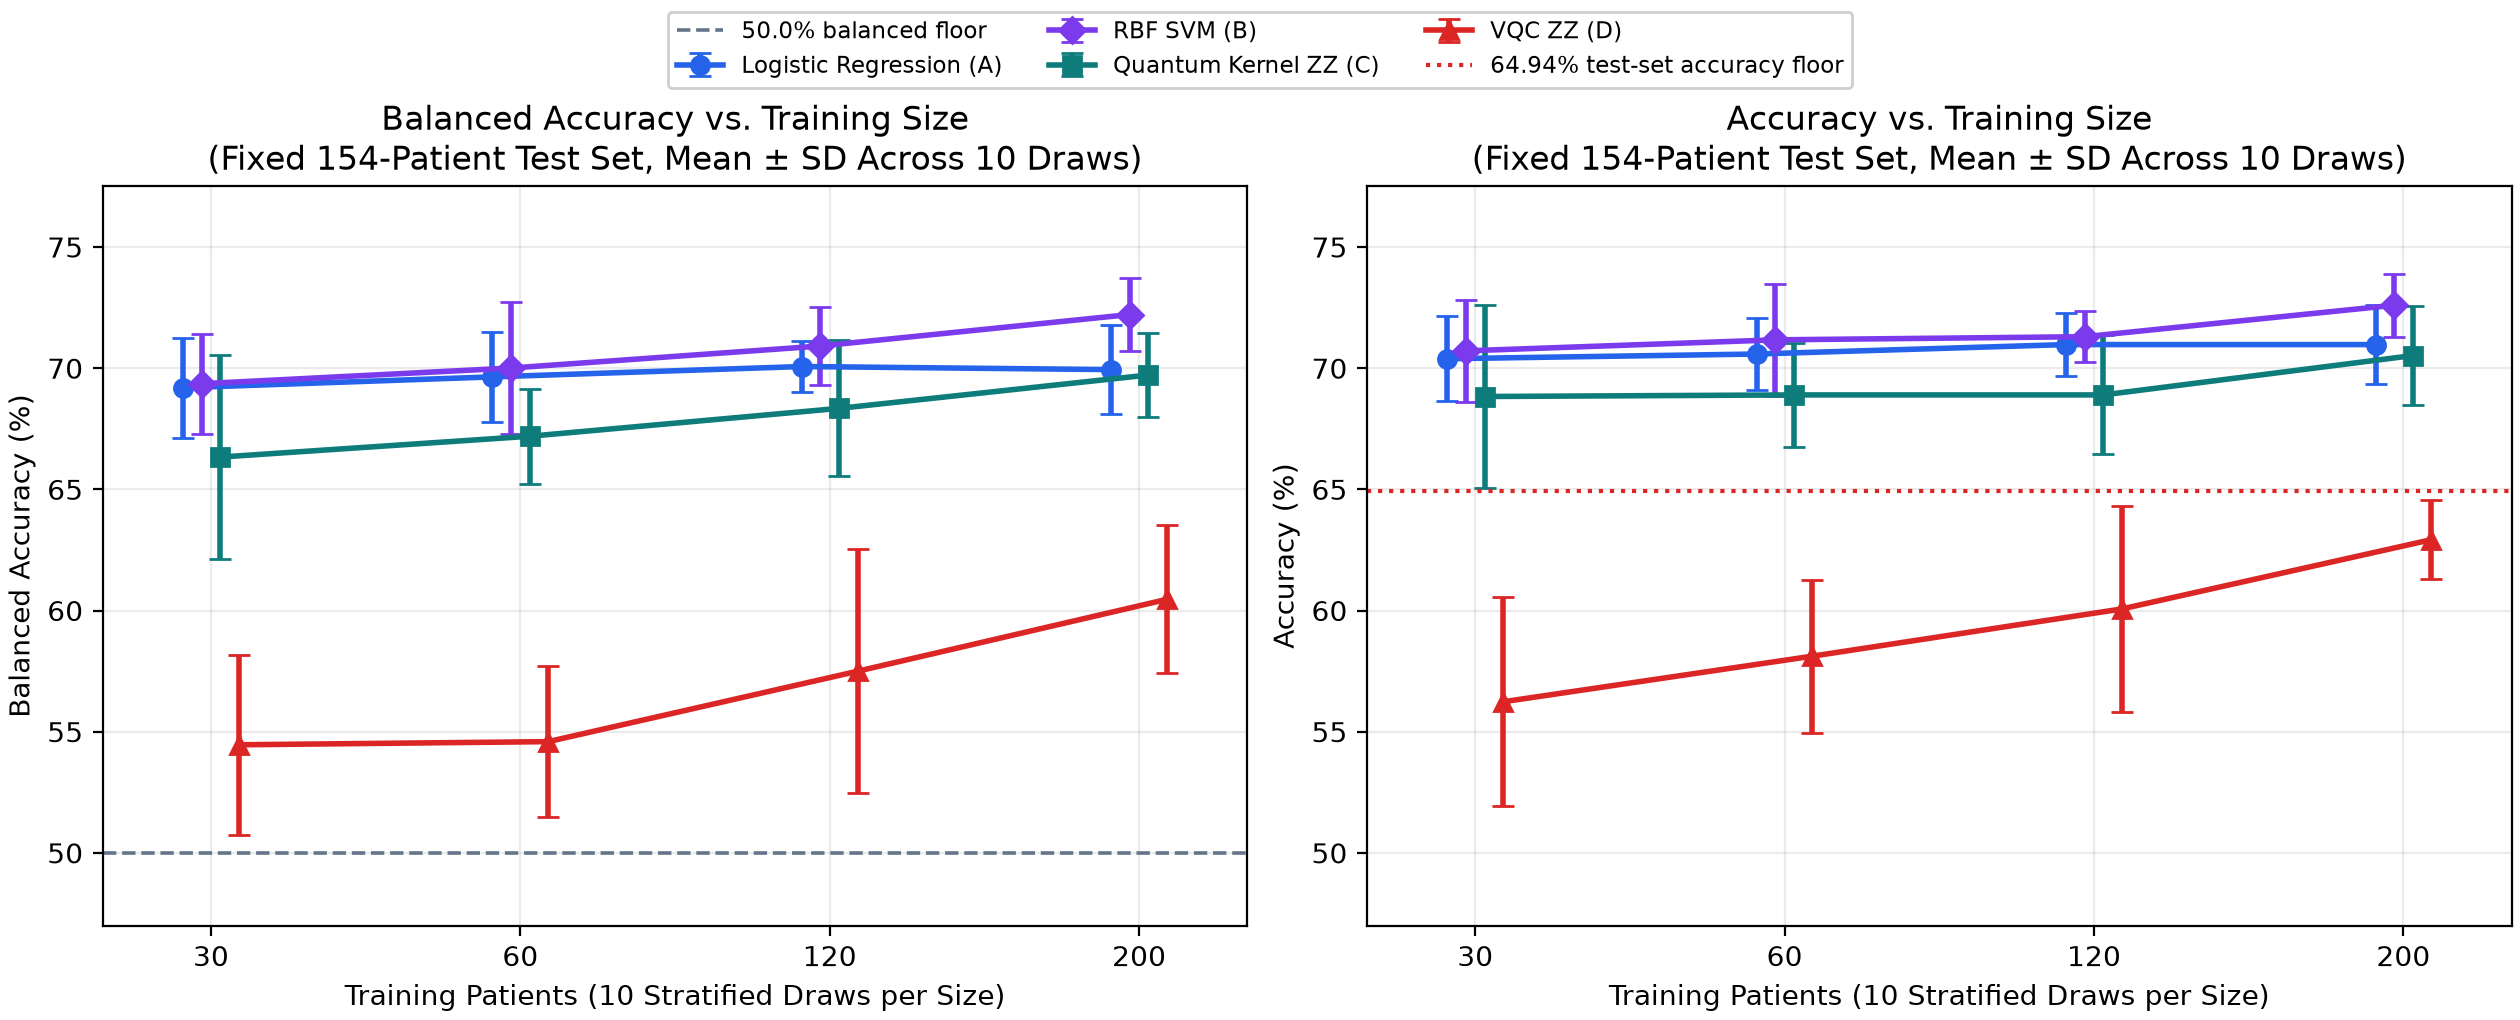

Saved combined figure: C:\Users\Lenovo\dev\Quantum Computing Competition\Quantum\figures\exp2_trainsize.png


In [5]:
TRAIN_SIZES = (30, 60, 120, 200)
_, te_fixed_idx = get_fixed_test_split(X, y)
_, te_counts = np.unique(y[te_fixed_idx], return_counts=True)
fixed_test_floor_acc = float(te_counts.max() / len(te_fixed_idx)) * 100.0
print(f"Fixed 20% test set: {len(te_fixed_idx)} patients | accuracy majority floor = {fixed_test_floor_acc:.2f}%")

rbf_exp2_all = pd.read_csv(RESULTS_DIR / "exp2_trainsize_rbf.csv")
EXP2_LOADERS = [
    ("Logistic Regression (A)", "#2563EB", "o", lambda s: pd.read_csv(RESULTS_DIR / f"exp2_logreg_n{s}.csv")),
    ("RBF SVM (B)", "#7C3AED", "D", lambda s: rbf_exp2_all[rbf_exp2_all["n_train"] == s].copy()),
    ("Quantum Kernel ZZ (C)", "#0E7C7B", "s", lambda s: pd.read_csv(RESULTS_DIR / f"exp2_qkernel_n{s}.csv")),
    ("VQC ZZ (D)", "#DC2626", "^", lambda s: pd.read_csv(RESULTS_DIR / "experiments" / f"exp2_vqc_n{s}_10draws.csv")),
]

exp2_data = {}
exp2_rows = []
for label, color, marker, loader in EXP2_LOADERS:
    exp2_data[label] = {}
    tuned_set = set()
    row_dict = {"Model": label}
    for s in TRAIN_SIZES:
        df_s = loader(s)
        assert len(df_s) == 10, f"Expected 10 draws for {label} n={s}, got {len(df_s)}"
        tuned_set.update(df_s["best_params"].unique().tolist())
        exp2_data[label][s] = df_s
        bm = float(df_s["balanced_accuracy"].mean()) * 100.0
        bs = float(df_s["balanced_accuracy"].std(ddof=1)) * 100.0
        am = float(df_s["accuracy"].mean()) * 100.0
        a_s = float(df_s["accuracy"].std(ddof=1)) * 100.0
        row_dict[f"n={s} (Bal Acc)"] = f"{bm:.1f}% ± {bs:.1f}%"
        row_dict[f"n={s} (Acc)"] = f"{am:.1f}% ± {a_s:.1f}%"
    row_dict["Reused fixed_params"] = ", ".join(sorted(tuned_set))
    exp2_rows.append(row_dict)

display(pd.DataFrame(exp2_rows))

# Figure 2: figures/exp2_trainsize.png
fig2, (ax_bal, ax_acc) = plt.subplots(1, 2, figsize=(12.6, 5.1), dpi=200, layout="constrained")
x_idx = np.arange(len(TRAIN_SIZES), dtype=float)
dx_vals = np.linspace(-0.09, 0.09, len(EXP2_LOADERS))

for (label, color, marker, _), dx in zip(EXP2_LOADERS, dx_vals):
    bal_m = [float(exp2_data[label][s]["balanced_accuracy"].mean()) * 100.0 for s in TRAIN_SIZES]
    bal_s = [float(exp2_data[label][s]["balanced_accuracy"].std(ddof=1)) * 100.0 for s in TRAIN_SIZES]
    acc_m = [float(exp2_data[label][s]["accuracy"].mean()) * 100.0 for s in TRAIN_SIZES]
    acc_s = [float(exp2_data[label][s]["accuracy"].std(ddof=1)) * 100.0 for s in TRAIN_SIZES]

    ax_bal.errorbar(
        x_idx + dx, bal_m, yerr=bal_s, marker=marker, linewidth=2.0, markersize=6.5,
        capsize=4, color=color, label=label,
    )
    ax_acc.errorbar(
        x_idx + dx, acc_m, yerr=acc_s, marker=marker, linewidth=2.0, markersize=6.5,
        capsize=4, color=color,
    )

ax_bal.axhline(
    BALANCED_CHANCE_FLOOR * 100.0,
    color="#64748B",
    linestyle="--",
    linewidth=1.3,
    label="50.0% balanced floor",
)
ax_acc.axhline(
    fixed_test_floor_acc,
    color="#DC2626",
    linestyle=":",
    linewidth=1.5,
    label=f"{fixed_test_floor_acc:.2f}% test-set accuracy floor",
)

ax_bal.set(
    xticks=x_idx,
    xticklabels=[str(s) for s in TRAIN_SIZES],
    xlabel="Training Patients (10 Stratified Draws per Size)",
    ylabel="Balanced Accuracy (%)",
    title="Balanced Accuracy vs. Training Size\n(Fixed 154-Patient Test Set, Mean ± SD Across 10 Draws)",
    xlim=(-0.35, 3.35),
    ylim=(47.0, 77.5),
)
ax_bal.grid(alpha=0.25)

ax_acc.set(
    xticks=x_idx,
    xticklabels=[str(s) for s in TRAIN_SIZES],
    xlabel="Training Patients (10 Stratified Draws per Size)",
    ylabel="Accuracy (%)",
    title="Accuracy vs. Training Size\n(Fixed 154-Patient Test Set, Mean ± SD Across 10 Draws)",
    xlim=(-0.35, 3.35),
    ylim=(47.0, 77.5),
)
ax_acc.grid(alpha=0.25)

handles_bal, labels_bal = ax_bal.get_legend_handles_labels()
handles_acc, labels_acc = ax_acc.get_legend_handles_labels()
fig2.legend(
    handles_bal + [handles_acc[-1]],
    labels_bal + [labels_acc[-1]],
    loc="outside upper center",
    ncol=3,
    fontsize=8.3,
    framealpha=0.95,
)

exp2_fig_path = FIGURES_DIR / "exp2_trainsize.png"
fig2.savefig(exp2_fig_path, dpi=200)
plt.close(fig2)
display(Image(filename=str(exp2_fig_path), width=920))
print(f"Saved combined figure: {exp2_fig_path}")


**What Experiment 2 showed:** Neither quantum model needed fewer patients than the classical baselines — **RBF SVM** and **Logistic Regression** led at every size from `30` to `200` (`69.2–72.2%` balanced accuracy), with Quantum Kernel catching up smoothly (`66.3% -> 69.7%`, spread dropping from `4.2%` to `1.7%`). **ZZ VQC** gained `+6.0` balanced-accuracy points (`54.5% -> 60.5%`), though it started near coin-flip chance at `30`–`60` patients (in part because smaller training sets give Adam fewer mini-batch steps per epoch at batch size `32`, in addition to the ZZ encoding bottleneck seen in Experiment 3).


## 5. Experiment 3 — How Data Enters the Circuit (`Angle` vs. `ZZ` Encoding)

Both quantum models were compared head-to-head when changing **only** the data encoding block from the entangled 2-repetition `ZZ` map to simple single-qubit rotations (`RY` for the Quantum Kernel, `RX` for the VQC — no entanglement):
- **Quantum Kernel (C):** Because simple `RY` encoding has **no entanglement**, its quantum fidelity kernel can be computed classically by a closed-form product of cosines.
- **VQC (D):** Switching from `ZZ` to `RX` Angle encoding triggered the biggest discovery of the project (backed by Yousef's Exam-0 underfitting check: training balanced accuracy rose from `0.604` on `ZZ` to `0.718` on `Angle`).


,Model & Scope,Angle Bal Acc,ZZ Bal Acc,Diff (Angle - ZZ),p-value,Time (Angle vs ZZ),Conclusion
0,Quantum Kernel (5 splits),73.82% ± 3.08%,72.01% ± 2.27%,+1.80%,0.5006,0.25s vs 0.82s,no significant difference found
1,Quantum Kernel (25 splits),74.68% ± 3.99%,73.97% ± 3.50%,+0.71%,0.6773,0.26s vs 0.83s,no significant difference found
2,VQC (5 splits),69.96% ± 3.98%,61.43% ± 2.76%,+8.53%,0.0011,303.91s vs 360.61s,significant difference found (p < 0.05)
3,VQC (25 splits),70.56% ± 3.66%,63.07% ± 4.65%,+7.49%,0.0160,194.92s vs 366.36s,significant difference found (p < 0.05)


=== Quantum Kernel Spread (Angle vs. ZZ across 5 train splits) | Angle vs. classical product-of-cosines max diff = 3.89e-15 ===


,encoding,gamma,kernel_mean_mean,kernel_mean_std,kernel_var_mean,kernel_var_std
0,angle,0.5,0.646091,0.005112,0.030709,0.000628
1,angle,1.0,0.229840,0.005296,0.045568,0.000963
2,zz,0.5,0.405912,0.005119,0.057394,0.001002
3,zz,1.0,0.038511,0.001111,0.007001,0.000254


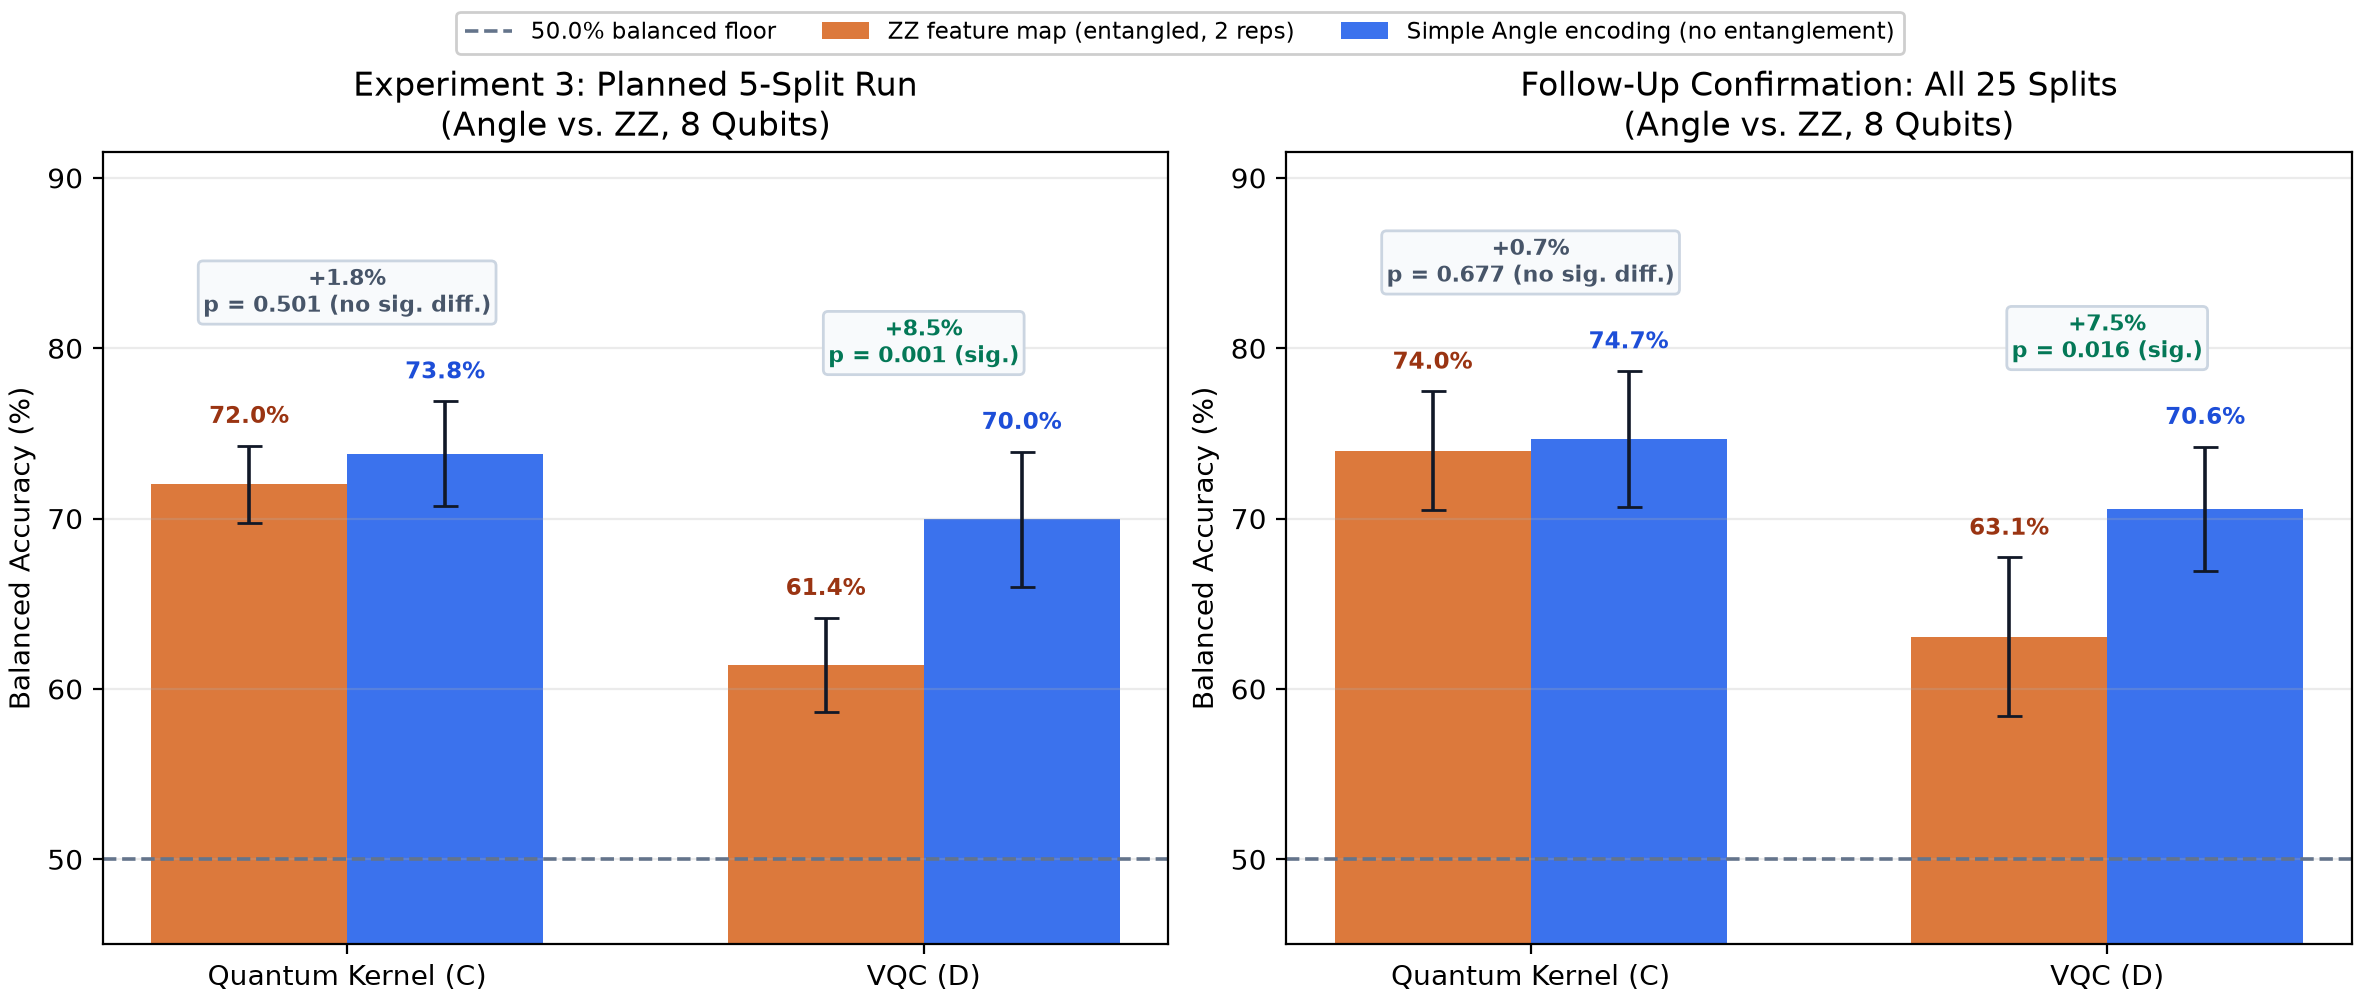

Saved combined figure: C:\Users\Lenovo\dev\Quantum Computing Competition\Quantum\figures\exp3_encoding.png


In [6]:
exp3_specs = [
    ("Quantum Kernel (5 splits)", RESULTS_DIR / "exp3_qkernel_angle.csv", RESULTS_DIR / "qkernel.csv", True),
    ("Quantum Kernel (25 splits)", RESULTS_DIR / "qkernel_angle.csv", RESULTS_DIR / "qkernel.csv", False),
    ("VQC (5 splits)", RESULTS_DIR / "experiments" / "exp3_vqc_angle_5ex.csv", RESULTS_DIR / "vqc_zz_25.csv", True),
    ("VQC (25 splits)", RESULTS_DIR / "vqc_angle_25.csv", RESULTS_DIR / "vqc_zz_25.csv", False),
]

exp3_cmp = {}
exp3_rows = []
for key, ang_path, zz_path, slice5 in exp3_specs:
    df_ang = pd.read_csv(ang_path)
    df_zz = pd.read_csv(zz_path)
    if slice5:
        df_zz = df_zz.iloc[:EXPERIMENT_EVAL_SPLITS].copy()
    assert len(df_ang) == len(df_zz)
    res = compare_models(df_ang, df_zz, metric="balanced_accuracy")
    exp3_cmp[key] = (df_ang, df_zz, res)
    exp3_rows.append(
        {
            "Model & Scope": key,
            "Angle Bal Acc": f"{res['mean_a']*100:.2f}% ± {df_ang['balanced_accuracy'].std(ddof=1)*100:.2f}%",
            "ZZ Bal Acc": f"{res['mean_b']*100:.2f}% ± {df_zz['balanced_accuracy'].std(ddof=1)*100:.2f}%",
            "Diff (Angle - ZZ)": f"{res['mean_diff']*100:+.2f}%",
            "p-value": f"{res['p_value']:.4f}",
            "Time (Angle vs ZZ)": f"{df_ang['train_time_sec'].mean():.2f}s vs {df_zz['train_time_sec'].mean():.2f}s",
            "Conclusion": res["conclusion"],
        }
    )

display(pd.DataFrame(exp3_rows))

spread_exp3_df, _, classical_max_diff = compute_exp3_kernel_spread(n_splits=EXPERIMENT_EVAL_SPLITS)
print(
    "=== Quantum Kernel Spread (Angle vs. ZZ across 5 train splits) | "
    f"Angle vs. classical product-of-cosines max diff = {classical_max_diff:.2e} ==="
)
display(spread_exp3_df)

# Figure 3: figures/exp3_encoding.png
fig3, (ax_5, ax_25) = plt.subplots(1, 2, figsize=(11.8, 5.0), dpi=200, layout="constrained")


def _plot_exp3_panel(ax, qk_key: str, vqc_key: str, panel_title: str) -> None:
    x = np.arange(2, dtype=float)
    width = 0.34
    pairs = [exp3_cmp[qk_key], exp3_cmp[vqc_key]]

    zz_means = [float(p[1]["balanced_accuracy"].mean()) * 100.0 for p in pairs]
    zz_stds = [float(p[1]["balanced_accuracy"].std(ddof=1)) * 100.0 for p in pairs]
    ang_means = [float(p[0]["balanced_accuracy"].mean()) * 100.0 for p in pairs]
    ang_stds = [float(p[0]["balanced_accuracy"].std(ddof=1)) * 100.0 for p in pairs]

    b_zz = ax.bar(
        x - width / 2, zz_means, width, yerr=zz_stds, capsize=4.5,
        color="#D96B27", alpha=0.90, label="ZZ feature map (entangled, 2 reps)",
        error_kw={"ecolor": "#111827", "elinewidth": 1.3},
    )
    b_ang = ax.bar(
        x + width / 2, ang_means, width, yerr=ang_stds, capsize=4.5,
        color="#2563EB", alpha=0.90, label="Simple Angle encoding (no entanglement)",
        error_kw={"ecolor": "#111827", "elinewidth": 1.3},
    )

    for bar, mv, sv in zip(b_zz, zz_means, zz_stds):
        ax.text(
            bar.get_x() + bar.get_width() / 2, mv + sv + 1.0, f"{mv:.1f}%",
            ha="center", va="bottom", fontsize=8.4, fontweight="bold", color="#9A3412",
        )
    for bar, mv, sv in zip(b_ang, ang_means, ang_stds):
        ax.text(
            bar.get_x() + bar.get_width() / 2, mv + sv + 1.0, f"{mv:.1f}%",
            ha="center", va="bottom", fontsize=8.4, fontweight="bold", color="#1D4ED8",
        )

    for idx, (_, _, res) in enumerate(pairs):
        y_top = max(zz_means[idx] + zz_stds[idx], ang_means[idx] + ang_stds[idx]) + 4.8
        tag = f"p = {res['p_value']:.3f} (sig.)" if res["p_value"] < 0.05 else f"p = {res['p_value']:.3f} (no sig. diff.)"
        ax.text(
            x[idx], y_top, f"{res['mean_diff']*100:+.1f}%\n{tag}",
            ha="center", va="bottom", fontsize=8.0, fontweight="bold",
            color="#047857" if res["p_value"] < 0.05 else "#475569",
            bbox=dict(boxstyle="round,pad=0.22", facecolor="#F8FAFC", edgecolor="#CBD5E1"),
        )

    ax.axhline(BALANCED_CHANCE_FLOOR * 100.0, color="#64748B", linestyle="--", linewidth=1.3, label="50.0% balanced floor")
    ax.set(
        xticks=x,
        xticklabels=["Quantum Kernel (C)", "VQC (D)"],
        ylabel="Balanced Accuracy (%)",
        title=panel_title,
        ylim=(45.0, 91.5),
    )
    ax.grid(axis="y", alpha=0.25)


_plot_exp3_panel(ax_5, "Quantum Kernel (5 splits)", "VQC (5 splits)", "Experiment 3: Planned 5-Split Run\n(Angle vs. ZZ, 8 Qubits)")
_plot_exp3_panel(ax_25, "Quantum Kernel (25 splits)", "VQC (25 splits)", "Follow-Up Confirmation: All 25 Splits\n(Angle vs. ZZ, 8 Qubits)")

handles, labels = ax_5.get_legend_handles_labels()
fig3.legend(handles, labels, loc="outside upper center", ncol=3, fontsize=8.4, framealpha=0.95)

exp3_fig_path = FIGURES_DIR / "exp3_encoding.png"
fig3.savefig(exp3_fig_path, dpi=200)
plt.close(fig3)
display(Image(filename=str(exp3_fig_path), width=920))
print(f"Saved combined figure: {exp3_fig_path}")


**What Experiment 3 showed:**
- **Quantum Kernel:** Dropping entanglement gave **no significant difference found** (`p = 0.501` on 5 splits, `p = 0.677` across all 25 splits) and ran **> 3× faster** (`0.26s` vs `0.83s`). Worse for quantum advantage claims on Pima: the unentangled Angle kernel matched a purely classical formula to machine precision (`< 1e-14` max error).
- **VQC:** Simply swapping `ZZ` out for single-qubit `RX` rotations boosted balanced accuracy by **`+8.53%`** on 5 splits (`p = 0.0011`) and **`+7.49%`** across all 25 splits (`p = 0.0160`), and cut runtime nearly in half (`366.4s -> 194.9s`). Hypothesis: `2`-repetition `ZZ` entangling angles scramble the 8-qubit input before 2 variational layers can untangle the decision boundary within `40` Adam epochs.


## 6. Experiment 5 — Artificial Curved-Data Control (`make_moons`, `2` Qubits)

Why didn't the `ZZ` Quantum Kernel beat Logistic Regression on Pima Diabetes? Could our circuit simply be unable to learn curved boundaries? To check, Khaled ran a **positive control on artificial `make_moons` data** (`768` points, the same size as Pima, `noise = 0.2`, `2` features = `2` qubits, first `5` splits) comparing the saved `ZZ` Quantum Kernel (`results/exp5_qkernel_moons.csv`) against the exact frozen Logistic Regression and Angle Kernel baselines on identical splits (run in a temporary folder below so no extra CSVs are written to `results/`).


,Model (Artificial make_moons),Accuracy,Balanced Accuracy,Macro F1
0,"ZZ Quantum Kernel (2q, saved)",93.88% ± 1.75%,93.88% ± 1.74%,93.88% ± 1.75%
1,"Angle Quantum Kernel (2q RY, ref)",86.46% ± 2.60%,86.44% ± 2.60%,86.42% ± 2.61%
2,Logistic Regression (Linear ref),85.68% ± 3.36%,85.66% ± 3.35%,85.65% ± 3.35%


ZZ vs Logistic Regression: diff=+8.21%, p=0.0203 -> significant difference found (p < 0.05)
ZZ vs Angle Kernel:        diff=+7.44%, p=0.0099 -> significant difference found (p < 0.05)


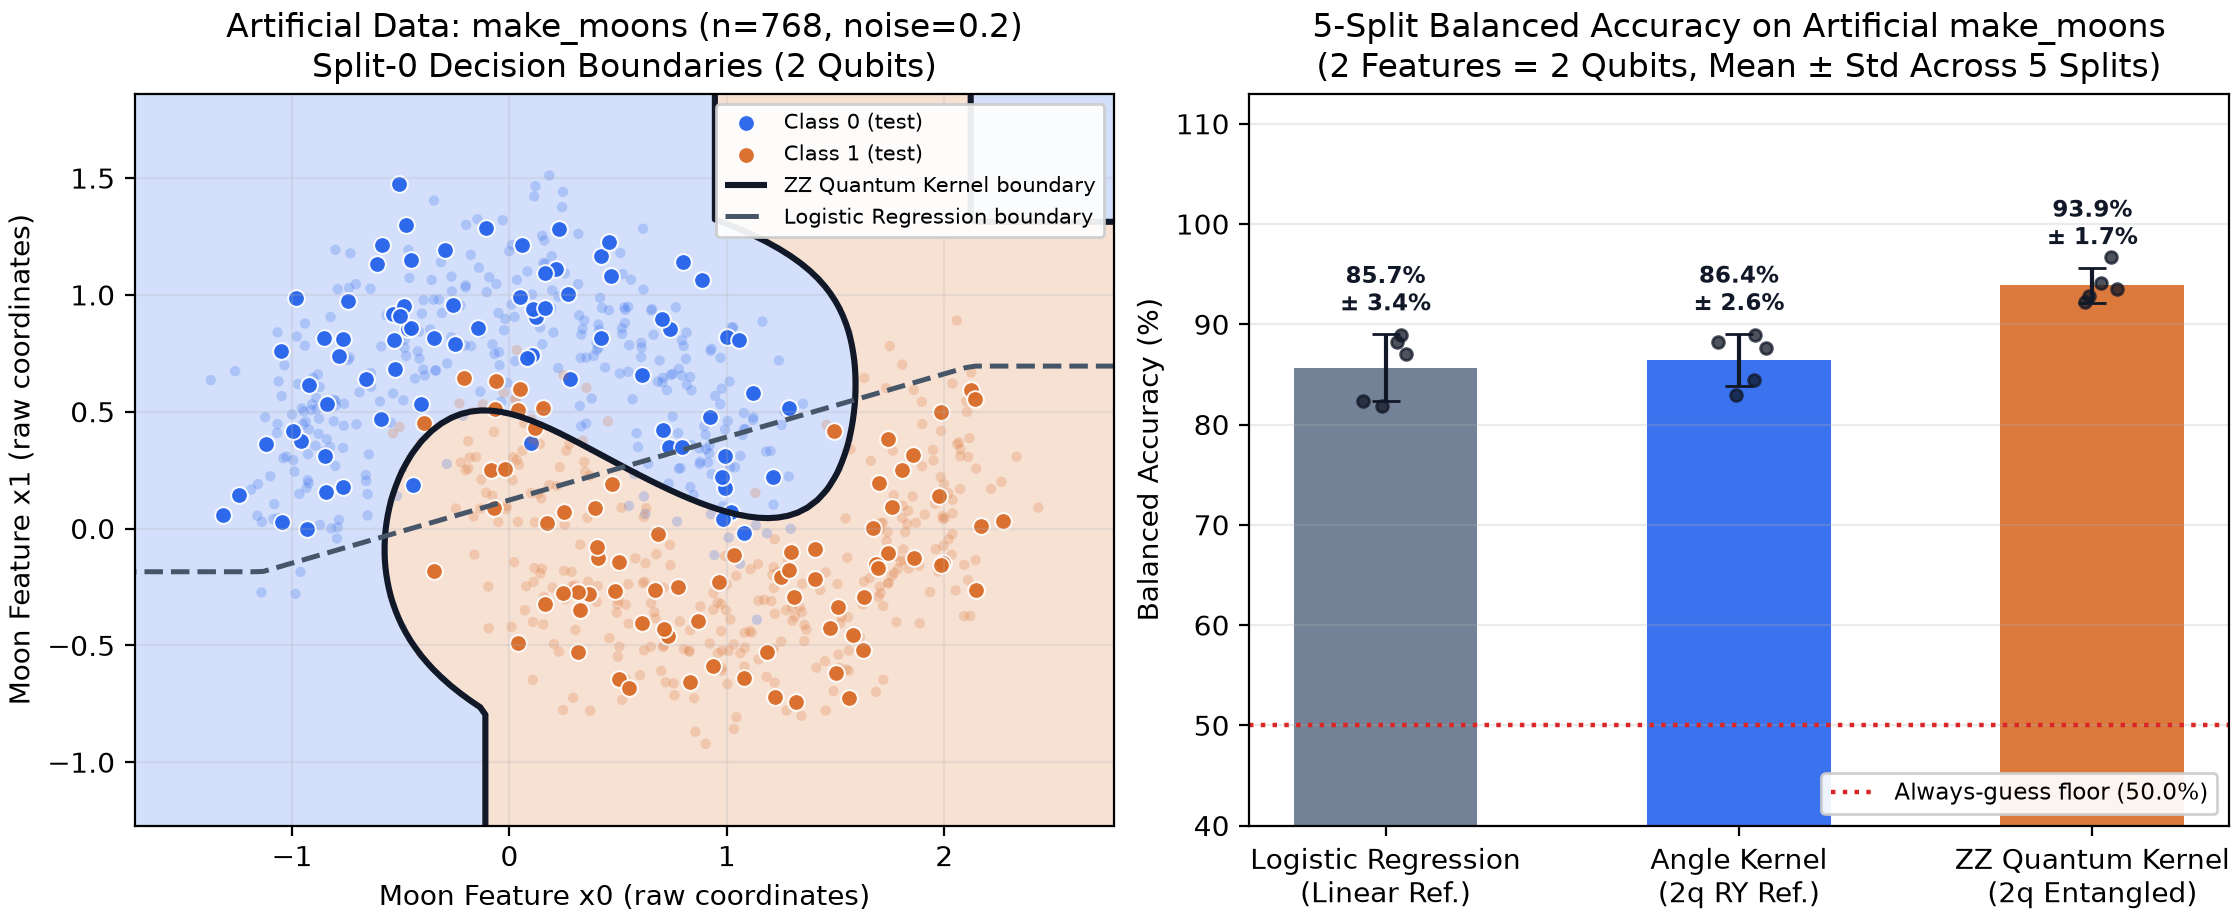

In [7]:
X_moons, y_moons = make_moons_dataset()
zz_moons_df = pd.read_csv(RESULTS_DIR / "exp5_qkernel_moons.csv")
assert len(zz_moons_df) == 5

with tempfile.TemporaryDirectory(prefix="nb-moons-ref-") as tmp_dir:
    logreg_moons_df = evaluate(
        "nb_moons_logreg",
        make_logreg_model,
        LOGREG_PARAM_GRID,
        n_features=2,
        X=X_moons,
        y=y_moons,
        zero_as_missing_cols=(),
        n_splits_to_run=EXPERIMENT_EVAL_SPLITS,
        results_dir=tmp_dir,
    )["results"]
    angle_moons_df = evaluate(
        "nb_moons_angle",
        lambda: make_qkernel_model(encoding="angle"),
        QKERNEL_PARAM_GRID,
        n_features=2,
        X=X_moons,
        y=y_moons,
        zero_as_missing_cols=(),
        n_splits_to_run=EXPERIMENT_EVAL_SPLITS,
        results_dir=tmp_dir,
    )["results"]

moons_rows = []
for name, df in (
    ("ZZ Quantum Kernel (2q, saved)", zz_moons_df),
    ("Angle Quantum Kernel (2q RY, ref)", angle_moons_df),
    ("Logistic Regression (Linear ref)", logreg_moons_df),
):
    st = summarize_df(df)
    moons_rows.append(
        {
            "Model (Artificial make_moons)": name,
            "Accuracy": f"{st['acc_mean']:.2f}% ± {st['acc_std']:.2f}%",
            "Balanced Accuracy": f"{st['bal_mean']:.2f}% ± {st['bal_std']:.2f}%",
            "Macro F1": f"{st['f1_mean']:.2f}% ± {st['f1_std']:.2f}%",
        }
    )
display(pd.DataFrame(moons_rows))

cmp_m_lr = compare_models(zz_moons_df, logreg_moons_df, metric="balanced_accuracy")
cmp_m_ang = compare_models(zz_moons_df, angle_moons_df, metric="balanced_accuracy")
print(
    f"ZZ vs Logistic Regression: diff={cmp_m_lr['mean_diff']*100:+.2f}%, "
    f"p={cmp_m_lr['p_value']:.4f} -> {cmp_m_lr['conclusion']}"
)
print(
    f"ZZ vs Angle Kernel:        diff={cmp_m_ang['mean_diff']*100:+.2f}%, "
    f"p={cmp_m_ang['p_value']:.4f} -> {cmp_m_ang['conclusion']}"
)

exp5_png = FIGURES_DIR / "exp5_qkernel.png"
if exp5_png.exists():
    display(Image(filename=str(exp5_png), width=900))


**What Experiment 5 proves (and its limit):** Clearly labeled as **artificial data**, `ZZ` Quantum Kernel scored **`93.88% ± 1.74%`** balanced accuracy, beating both linear Logistic Regression (`+8.21%`, `p = 0.0203`) and unentangled Angle encoding (`+7.44%`, `p = 0.0099`). A classical RBF SVM, which also draws curved boundaries, scored `96.10% ± 1.71%` (`results/exp5_rbf_svm_moons.csv`), `2.22` points above the `ZZ` kernel; no significant difference found (`p = 0.1887`, 5 exams), so on this data the quantum kernel matches a good classical curved model rather than beating it. This proves our quantum pipeline **can** learn curved structure when strong curves exist — making *"our models can't see curves"* unlikely as the reason Pima tied at ~74–75%. *(Open limit: by itself, this test still cannot separate "Pima is mostly linear" from "Pima's classes overlap too heavily in 8D".)*


## 7. End-to-End Pipeline Verification (`quick=True` Smoke Test)

To prove every classifier file plugs cleanly into `src/evaluate.py`, this cell runs all four models live inside a **temporary directory** (`results/` files on disk are never touched or overwritten).

- Set `RUN_FULL_VQC_QUICK = False` (default): runs full `quick=True` (`5` splits) for Logistic Regression, RBF SVM, and Quantum Kernel, plus a fast `1`-split `4`-qubit `3`-epoch VQC smoke pass through `evaluate()` (`~5 seconds` total).
- Flip `RUN_FULL_VQC_QUICK = True` to run `quick=True` (`5` splits, `8` qubits) for VQC as well (`~10 minutes` on CPU).
- **Smoke-test numbers below verify code wiring only and are NEVER reported as benchmark results.**


In [8]:
RUN_FULL_VQC_QUICK = False  # Set True for full 5-split 8-qubit VQC quick=True (~10 min on CPU)

print("SMOKE TEST ONLY (outputs written to temporary folder; never reported as results)")
smoke_rows = []

with tempfile.TemporaryDirectory(prefix="nb-smoke-") as tmp_dir:
    quick_jobs = [
        ("Logistic Regression (A)", make_logreg_model, LOGREG_PARAM_GRID, {"quick": True}),
        ("RBF SVM (B)", make_rbf_model, RBF_PARAM_GRID, {"quick": True}),
        ("Quantum Kernel ZZ (C)", make_qkernel_model, QKERNEL_PARAM_GRID, {"quick": True}),
    ]
    if RUN_FULL_VQC_QUICK:
        quick_jobs.append(("VQC ZZ (D)", make_vqc_model, VQC_PARAM_GRID, {"quick": True}))
    else:
        quick_jobs.append(
            (
                "VQC ZZ (D, 1-split 4q smoke)",
                make_vqc_model,
                VQC_PARAM_GRID,
                {
                    "n_features": 4,
                    "n_splits_to_run": 1,
                    "fixed_params": {"lr": 0.05, "epochs": 3},
                },
            )
        )

    for label, maker, grid, extra_kwargs in quick_jobs:
        t0 = time.perf_counter()
        summary = evaluate(
            name=label.lower().replace(" ", "_").replace("(", "").replace(")", "").replace(",", ""),
            make_model=maker,
            param_grid=grid,
            results_dir=tmp_dir,
            **extra_kwargs,
        )
        elapsed = time.perf_counter() - t0
        res_df = summary["results"]
        assert len(res_df) >= 1
        assert res_df["balanced_accuracy"].between(0.0, 1.0).all()
        assert res_df["accuracy"].between(0.0, 1.0).all()
        assert res_df.isna().sum().sum() == 0
        smoke_rows.append(
            {
                "Model": label,
                "Splits Run": summary["n_splits"],
                "Features": summary["n_features"],
                "Smoke Bal Acc (not reported)": f"{summary['balanced_accuracy_mean'] * 100:.1f}%",
                "Elapsed (s)": f"{elapsed:.2f}",
                "Contract Check": "PASS",
            }
        )

display(pd.DataFrame(smoke_rows))


SMOKE TEST ONLY (outputs written to temporary folder; never reported as results)


,Model,Splits Run,Features,Smoke Bal Acc (not reported),Elapsed (s),Contract Check
0,Logistic Regression (A),5,8,72.6%,0.24,PASS
1,RBF SVM (B),5,8,74.5%,0.41,PASS
2,Quantum Kernel ZZ (C),5,8,72.7%,4.18,PASS
3,"VQC ZZ (D, 1-split 4q smoke)",1,4,68.3%,0.93,PASS


## 8. Honest Summary, Limits & Combined Figures Inventory

### Key Takeaways for the Report & Presentation
1. **Fair tie near ~74–75% (`no significant difference found`):** Logistic Regression (`74.21%`), RBF SVM (`74.99%`), Quantum Kernel ZZ (`73.97%`), and Quantum Kernel Angle (`74.68%`) all beat the `65.10%` accuracy (`50.00%` balanced) floor cleanly, with no statistically significant gap between classical and quantum kernels on Pima Diabetes.
2. **Why `ZZ` Quantum Kernel did not beat classical models:** Removing entanglement completely (Angle `RY`) left the Pima score unchanged (`p = 0.677`) while cutting runtime by `> 3×`, and `kernel_stats()` showed off-diagonal variance dropping **`7.0×`** from `4` to `8` qubits at `gamma = 1.0`. Meanwhile, the artificial `make_moons` positive control (`93.88%` vs `85.66%`, `p = 0.0203`) confirmed the `ZZ` circuit *can* capture strong curves when they exist. A classical RBF SVM, which also draws curved boundaries, scored `96.10%` there, `2.22` points above the `ZZ` kernel; no significant difference found (`p = 0.1887`, 5 exams), so on that data the quantum kernel matches a good classical curved model rather than beating it.
3. **Why encoding mattered dramatically for VQC:** Under identical training settings, `ZZ` encoding caused the 8-qubit VQC to severely underfit (`63.07%` balanced accuracy, `366.4s`/split). Switching solely to single-qubit `RX` Angle encoding jumped VQC by `+7.49%` (`70.56%`, `p = 0.0160`) across all 25 splits, though it still trailed Logistic Regression (`-3.64%`, `p = 0.0105`).
4. **Data-efficiency & feature-count checks:** Neither quantum model outperformed classical baselines in low-data regimes (`30–200` training patients, Experiment 2), nor gained from using `8` features over the top `4` features (`p >= 0.33`, Experiment 1).

### Open Caveats to State Clearly
- **Relaxed screening rule:** Earlier dataset screening (`77.1%` LogReg vs `76.5%` RBF SVM) did not show RBF beating linear, and used different preprocessing (never reported as final results).
- **Tuning budget asymmetry:** VQC tuned `4` combinations (`lr`, `epochs`) instead of `8` due to `~6 min/split` simulator cost.
- **Experiment 2 tuning shortcut:** Every model tuned once on the `614`-patient training pool and reused `fixed_params` across sizes `30`–`200`; all draws shared one `154`-patient test set.
- **Experiment 1 coverage:** All four models, including RBF SVM (B), are included using identical selected columns on the first five splits. The 8-column references reuse the first five rows of the main results; the small sample of five splits limits statistical power.

### Combined Figures Saved by This Notebook
- `figures/main_comparison.png` — 25-split scores & log-scale runtime across all 6 runs
- `figures/exp1_qubits.png` — Experiment 1 balanced accuracy (`4, 6, 8` columns/qubits)
- `figures/exp1_kernel_spread.png` — Quantum Kernel off-diagonal mean & variance (`4 -> 8` qubits)
- `figures/exp2_trainsize.png` — Experiment 2 balanced accuracy & accuracy across `30–200` training patients (all 4 models)
- `figures/exp3_encoding.png` — Experiment 3 (`Angle` vs. `ZZ`) on both 5 splits and 25 splits
